In [2]:
# ── Imports ──────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import warnings
warnings.filterwarnings('ignore')

print("All imports successful")

# ── Load Data ─────────────────────────────────────────────────
fighter_details = pd.read_csv('raw_fighter_details.csv')
fight_data      = pd.read_csv('raw_total_fight_data.csv', sep=';')
preprocessed    = pd.read_csv('preprocessed_data.csv')

# ── Quick Sanity Check ────────────────────────────────────────
print(f"Fighter details:  {fighter_details.shape}")
print(f"Raw fight data:   {fight_data.shape}")
print(f"Preprocessed:     {preprocessed.shape}")

All imports successful
Fighter details:  (3596, 14)
Raw fight data:   (6012, 41)
Preprocessed:     (5902, 160)


In [3]:
# ── First look at the preprocessed data ──────────────────────
preprocessed.head()

,Winner,title_bout,B_avg_KD,B_avg_opp_KD,B_avg_SIG_STR_pct,B_avg_opp_SIG_STR_pct,B_avg_TD_pct,B_avg_opp_TD_pct,B_avg_SUB_ATT,B_avg_opp_SUB_ATT,...,B_Stance_Open Stance,B_Stance_Orthodox,B_Stance_Sideways,B_Stance_Southpaw,B_Stance_Switch,R_Stance_Open Stance,R_Stance_Orthodox,R_Stance_Sideways,R_Stance_Southpaw,R_Stance_Switch
0,Red,False,0.000000,0.0,0.420000,0.49500,0.330,0.36000,0.500000,1.000000,...,0,1,0,0,0,0,1,0,0,0
1,Red,False,0.500000,0.0,0.660000,0.30500,0.300,0.50000,1.500000,0.000000,...,0,1,0,0,0,0,1,0,0,0
2,Red,False,0.015625,0.0,0.450000,0.42750,0.250,0.20000,0.148468,0.098389,...,0,1,0,0,0,0,0,0,1,0
3,Blue,False,0.015625,0.0,0.450000,0.42750,0.250,0.20000,0.148468,0.098389,...,0,0,0,1,0,0,0,0,0,1
4,Blue,False,0.125000,0.0,0.535625,0.57875,0.185,0.16625,0.125000,0.187500,...,0,1,0,0,0,0,1,0,0,0


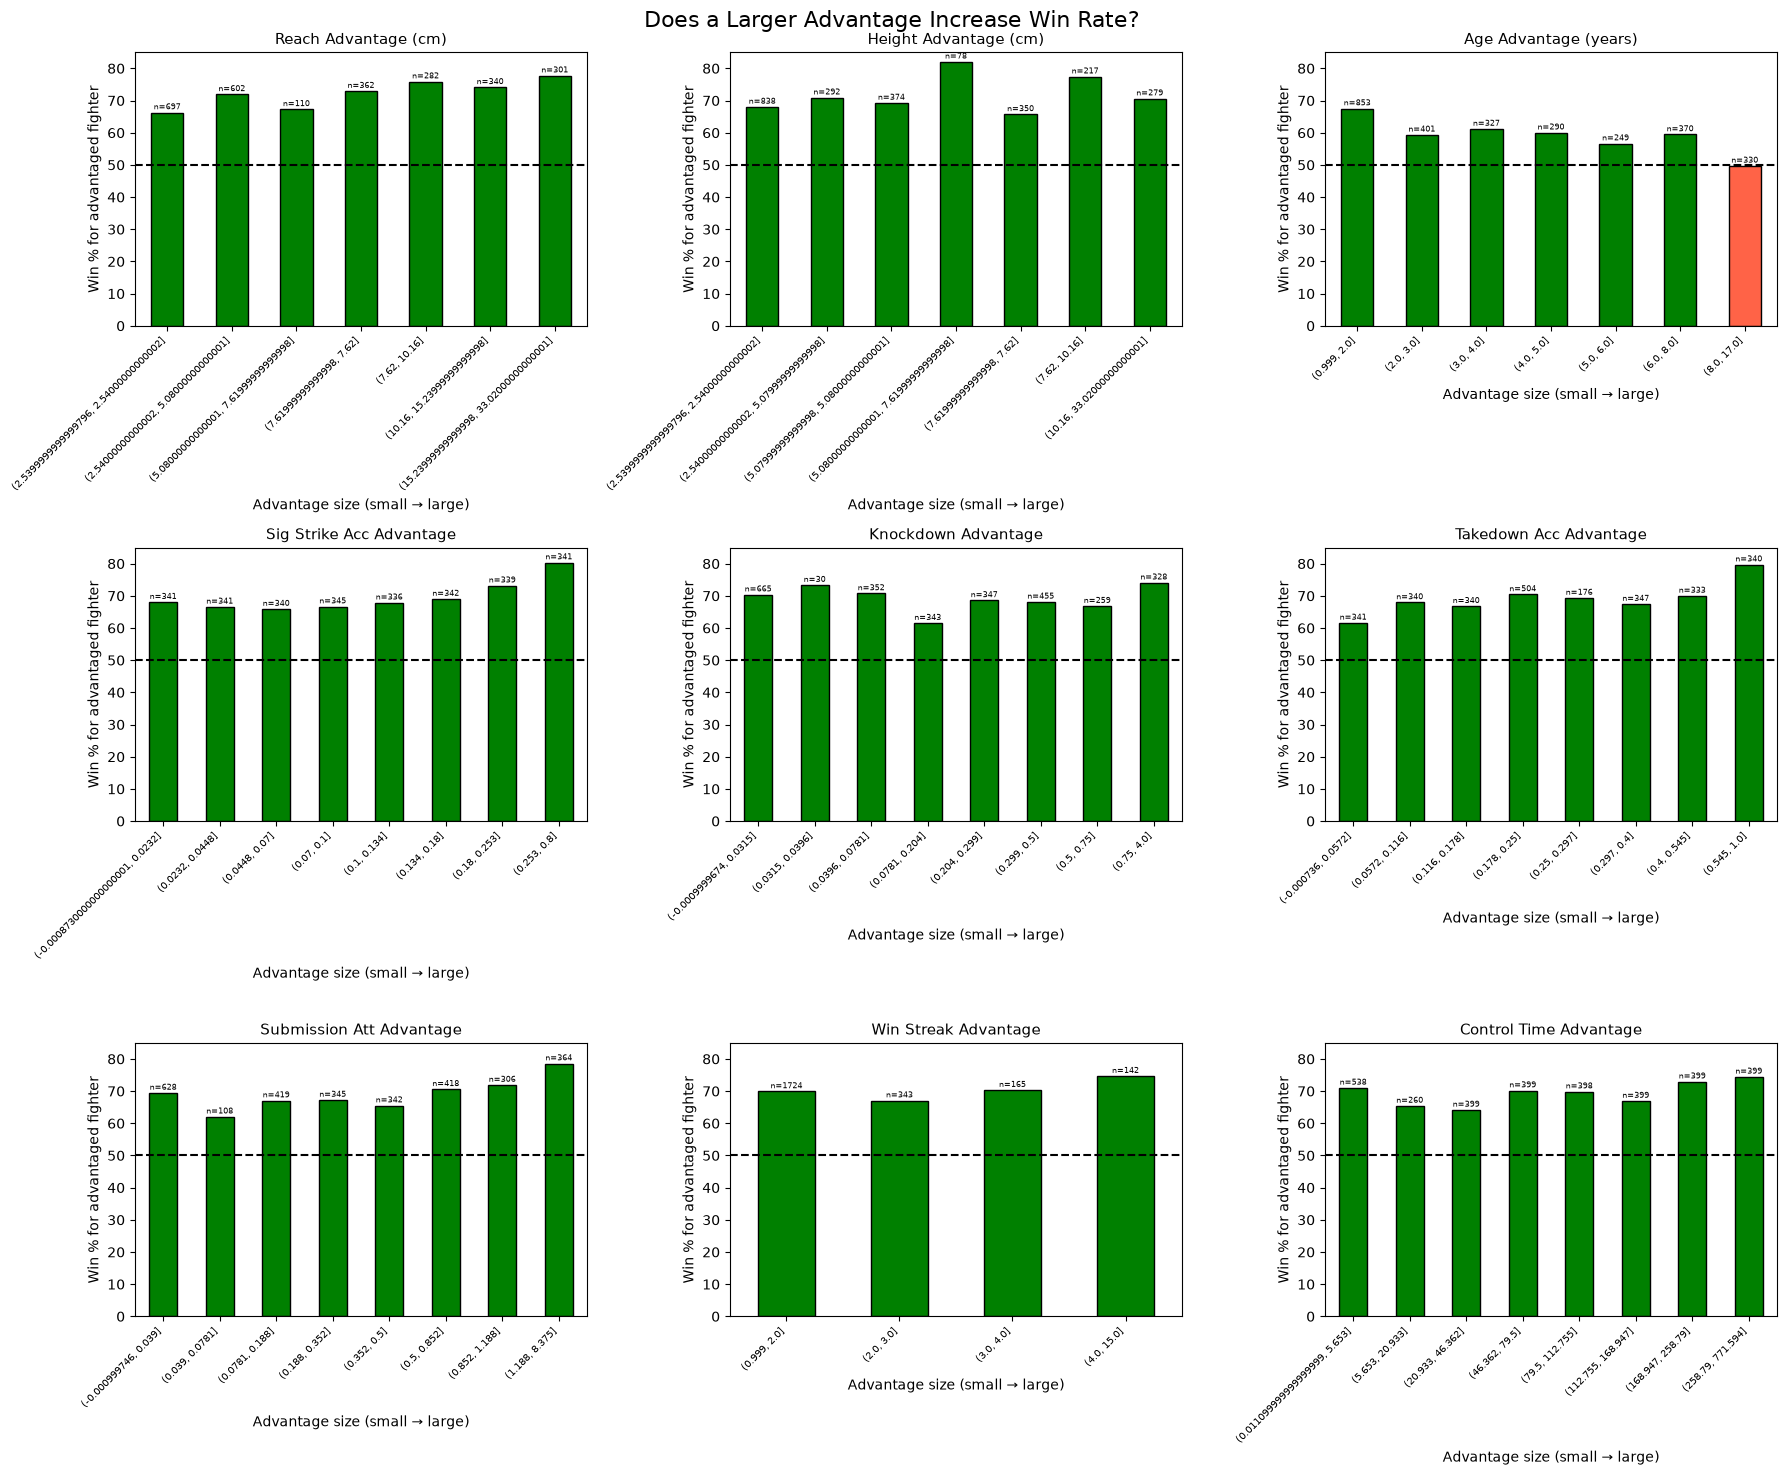

In [4]:
# ── Win Rate by Advantage (positive only, bias corrected) ─────

fig, axes = plt.subplots(3, 3, figsize=(18, 15))
fig.suptitle('Does a Larger Advantage Increase Win Rate?', fontsize=16)

advantages = [
    ('R_Reach_cms',                'B_Reach_cms',                 'Reach Advantage (cm)'),
    ('R_Height_cms',               'B_Height_cms',                'Height Advantage (cm)'),
    ('R_age',                      'B_age',                       'Age Advantage (years)'),
    ('R_avg_SIG_STR_pct',          'B_avg_SIG_STR_pct',           'Sig Strike Acc Advantage'),
    ('R_avg_KD',                   'B_avg_KD',                    'Knockdown Advantage'),
    ('R_avg_TD_pct',               'B_avg_TD_pct',                'Takedown Acc Advantage'),
    ('R_avg_SUB_ATT',              'B_avg_SUB_ATT',               'Submission Att Advantage'),
    ('R_current_win_streak',       'B_current_win_streak',        'Win Streak Advantage'),
    ('R_avg_CTRL_time(seconds)',    'B_avg_CTRL_time(seconds)',    'Control Time Advantage'),
]

df = preprocessed.copy()

for ax, (r_col, b_col, title) in zip(axes.flatten(), advantages):
    df['advantage'] = df[r_col] - df[b_col]

    # Did the fighter WITH the advantage win?
    df['adv_won'] = (
        ((df['advantage'] > 0) & (df['Winner'] == 'Red')) |
        ((df['advantage'] < 0) & (df['Winner'] == 'Blue'))
    ).astype(int)

    df_clean = df[['advantage', 'adv_won']].dropna()

    # Keep only positive advantages — the fighter who HAS the edge
    df_clean = df_clean[df_clean['advantage'] > 0]

    # Equal size buckets across positive range only
    df_clean['bin'] = pd.qcut(df_clean['advantage'], q=8, duplicates='drop')

    grouped  = df_clean.groupby('bin', observed=True)['adv_won']
    win_rate = grouped.mean() * 100
    counts   = grouped.count()

    colors = ['green' if v >= 50 else 'tomato' for v in win_rate]

    win_rate.plot(kind='bar', ax=ax, color=colors, edgecolor='black')
    ax.axhline(y=50, color='black', linestyle='--', linewidth=1.5)
    ax.set_title(title, fontsize=11)
    ax.set_ylabel('Win % for advantaged fighter')
    ax.set_xlabel('Advantage size (small → large)')
    ax.set_xticklabels([str(b) for b in win_rate.index], rotation=45, ha='right', fontsize=7)
    ax.set_ylim(0, 85)

    for i, (val, count) in enumerate(zip(win_rate, counts)):
        ax.text(i, val + 1, f'n={count}', ha='center', fontsize=6)

plt.tight_layout()
plt.show()

In [5]:
from scipy import stats

df = preprocessed.copy()

advantages = [
    ('R_Reach_cms',              'B_Reach_cms',              'Reach Advantage'),
    ('R_Height_cms',             'B_Height_cms',             'Height Advantage'),
    ('R_age',                    'B_age',                    'Age Advantage'),
    ('R_avg_SIG_STR_pct',        'B_avg_SIG_STR_pct',        'Sig Strike Acc Advantage'),
    ('R_avg_KD',                 'B_avg_KD',                 'Knockdown Advantage'),
    ('R_avg_TD_pct',             'B_avg_TD_pct',             'Takedown Acc Advantage'),
    ('R_avg_SUB_ATT',            'B_avg_SUB_ATT',            'Submission Att Advantage'),
    ('R_current_win_streak',     'B_current_win_streak',     'Win Streak Advantage'),
    ('R_avg_CTRL_time(seconds)', 'B_avg_CTRL_time(seconds)', 'Control Time Advantage'),
]

results = []

for r_col, b_col, title in advantages:
    df['advantage'] = df[r_col] - df[b_col]
    df['result']    = (df['Winner'] == 'Red').astype(int)
    
    df_clean = df[['advantage', 'result']].dropna()
    df_clean = df_clean[df_clean['advantage'] != 0]
    
    corr, pvalue = stats.pointbiserialr(df_clean['advantage'], df_clean['result'])
    
    results.append({
        'Factor':      title,
        'Correlation': round(corr, 4),
        'P-Value':     round(pvalue, 6),
        'N':           len(df_clean),
        'Significant': 'YES' if pvalue < 0.05 else 'NO'
    })

results_df = pd.DataFrame(results).sort_values('P-Value')
print(results_df.to_string(index=False))

                  Factor  Correlation  P-Value    N Significant
         Reach Advantage       0.1177 0.000000 5125         YES
           Age Advantage      -0.1763 0.000000 5445         YES
Sig Strike Acc Advantage       0.0643 0.000002 5439         YES
  Takedown Acc Advantage       0.0662 0.000002 5192         YES
  Control Time Advantage       0.0613 0.000003 5829         YES
        Height Advantage       0.0492 0.000591 4874         YES
Submission Att Advantage       0.0425 0.001991 5288         YES
    Win Streak Advantage       0.0471 0.003899 3750         YES
     Knockdown Advantage       0.0328 0.021477 4927         YES


In [6]:
# ── Fighter Quality Model (corner agnostic) ───────────────────

df = preprocessed.copy()

# ── Step 1: Build difference features ────────────────────────
features = {
    'reach_diff':      ('R_Reach_cms',              'B_Reach_cms'),
    'height_diff':     ('R_Height_cms',             'B_Height_cms'),
    'age_diff':        ('R_age',                    'B_age'),
    'sig_str_diff':    ('R_avg_SIG_STR_pct',        'B_avg_SIG_STR_pct'),
    'kd_diff':         ('R_avg_KD',                 'B_avg_KD'),
    'td_acc_diff':     ('R_avg_TD_pct',             'B_avg_TD_pct'),
    'sub_att_diff':    ('R_avg_SUB_ATT',            'B_avg_SUB_ATT'),
    'win_streak_diff': ('R_current_win_streak',     'B_current_win_streak'),
    'ctrl_time_diff':  ('R_avg_CTRL_time(seconds)', 'B_avg_CTRL_time(seconds)'),
}

for col_name, (r_col, b_col) in features.items():
    df[col_name] = df[r_col] - df[b_col]

feature_cols = list(features.keys())
df['result']  = (df['Winner'] == 'Red').astype(int)
df_model      = df[feature_cols + ['result']].dropna()

X = df_model[feature_cols]
y = df_model['result']

# ── Step 2: Train/Test Split ──────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ── Step 3: Scale & Train ─────────────────────────────────────
scaler    = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

model = LogisticRegression(random_state=42)
model.fit(X_train_s, y_train)

# ── Step 4: Get probabilities ─────────────────────────────────
probs    = model.predict_proba(X_test_s)
red_prob = probs[:, 1]
blue_prob= probs[:, 0]

# ── Step 5: Build results table ───────────────────────────────
test_df = df_model.iloc[X_test.index].copy()
test_df['red_prob']  = (red_prob  * 100).round(1)
test_df['blue_prob'] = (blue_prob * 100).round(1)

# Predicted winner = corner with higher probability
test_df['predicted'] = test_df.apply(
    lambda r: 'Red' if r['red_prob'] >= r['blue_prob'] else 'Blue', axis=1
)

# Actual winner
test_df['actual'] = test_df['result'].map({1: 'Red', 0: 'Blue'})

# Correct if predicted matches actual
test_df['correct'] = (test_df['predicted'] == test_df['actual']).map({True: '✓', False: '✗'})

# ── Step 6: Display ───────────────────────────────────────────
display_df = test_df[[
    'red_prob', 'blue_prob',
    'predicted', 'actual', 'correct'
]].copy()

display_df.columns = [
    'Red Win %', 'Blue Win %',
    'Predicted Winner', 'Actual Winner', 'Correct'
]

total   = len(test_df)
correct = (test_df['predicted'] == test_df['actual']).sum()
print(f"Prediction accuracy: {correct}/{total} ({correct/total:.1%})")
print(f"\nSample predictions (first 20 fights):")
print(display_df.head(20).to_string(index=False))

Prediction accuracy: 814/1181 (68.9%)

Sample predictions (first 20 fights):
 Red Win %  Blue Win % Predicted Winner Actual Winner Correct
      53.3        46.7              Red          Blue       ✗
      64.3        35.7              Red           Red       ✓
      66.7        33.3              Red           Red       ✓
      48.7        51.3             Blue          Blue       ✓
      70.4        29.6              Red           Red       ✓
      78.5        21.5              Red          Blue       ✗
      73.5        26.5              Red           Red       ✓
      69.8        30.2              Red           Red       ✓
      72.9        27.1              Red           Red       ✓
      57.6        42.4              Red           Red       ✓
      68.0        32.0              Red           Red       ✓
      73.3        26.7              Red           Red       ✓
      58.0        42.0              Red          Blue       ✗
      64.3        35.7              Red           Red  

In [7]:
coef_df = pd.DataFrame({
    'Feature':     feature_cols,
    'Coefficient': model.coef_[0]
}).sort_values('Coefficient', ascending=False)

print(coef_df.to_string(index=False))

        Feature  Coefficient
     reach_diff     0.304069
 ctrl_time_diff     0.106008
        kd_diff     0.093704
   sig_str_diff     0.080823
win_streak_diff     0.074692
    td_acc_diff     0.039580
   sub_att_diff     0.034671
    height_diff    -0.153605
       age_diff    -0.305616


In [8]:
from sklearn.metrics import brier_score_loss, log_loss
import numpy as np

# ── Get probabilities on test set ─────────────────────────────
probs_test = model.predict_proba(X_test_s)
red_probs  = probs_test[:, 1]

# ── Standard Metrics ──────────────────────────────────────────
ll    = log_loss(y_test, probs_test)
brier = brier_score_loss(y_test, red_probs)

print(f"{'='*40}")
print(f"  Model Evaluation")
print(f"{'='*40}")
print(f"  Accuracy:    {(model.predict(X_test_s) == y_test).mean():.1%}")
print(f"  Log Loss:    {ll:.4f}  (lower = better, random = 0.693)")
print(f"  Brier Score: {brier:.4f}  (lower = better, random = 0.250)")
print(f"{'='*40}")

# ── Penalty Analysis — how bad are our confident wrong calls ──
test_eval = pd.DataFrame({
    'actual':   y_test.values,
    'red_prob': red_probs,
})

test_eval['correct']    = (test_eval['red_prob'].round() == test_eval['actual'])
test_eval['confidence'] = test_eval['red_prob'].apply(
    lambda p: max(p, 1-p)  # how confident was the model (0.5 to 1.0)
)

# Brier score per prediction (individual penalty)
test_eval['brier_penalty'] = (test_eval['red_prob'] - test_eval['actual']) ** 2

# Bucket by confidence level
bins   = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
labels = ['50-60%', '60-70%', '70-80%', '80-90%', '90-100%']
test_eval['confidence_band'] = pd.cut(test_eval['confidence'], bins=bins, labels=labels)

summary = test_eval.groupby('confidence_band', observed=True).agg(
    Fights        = ('correct', 'count'),
    Correct       = ('correct', 'sum'),
    Win_Rate      = ('correct', 'mean'),
    Avg_Penalty   = ('brier_penalty', 'mean')
).reset_index()

summary['Win_Rate']    = (summary['Win_Rate'] * 100).round(1).astype(str) + '%'
summary['Avg_Penalty'] = summary['Avg_Penalty'].round(4)
summary.columns        = ['Confidence Band', 'Fights', 'Correct', 'Win Rate', 'Avg Brier Penalty']

print(f"\n  Penalty by Confidence Level:")
print(f"  (how often is the model right when it's confident?)")
print(f"{'='*60}")
print(summary.to_string(index=False))
print(f"{'='*60}")
print(f"\n  Worst confident wrong calls (model >75% confident, got it wrong):")
wrong_confident = test_eval[
    (test_eval['correct'] == False) & 
    (test_eval['confidence'] > 0.75)
].sort_values('confidence', ascending=False)

print(f"  {len(wrong_confident)} fights where model was >75% confident but wrong")
print(f"  Average penalty on these: {wrong_confident['brier_penalty'].mean():.4f}")

  Model Evaluation
  Accuracy:    68.9%
  Log Loss:    0.6078  (lower = better, random = 0.693)
  Brier Score: 0.2092  (lower = better, random = 0.250)

  Penalty by Confidence Level:
  (how often is the model right when it's confident?)
Confidence Band  Fights  Correct Win Rate  Avg Brier Penalty
         50-60%     260      157    60.4%             0.2421
         60-70%     417      266    63.8%             0.2297
         70-80%     401      314    78.3%             0.1709
         80-90%     102       76    74.5%             0.1939
        90-100%       1        1   100.0%             0.0068

  Worst confident wrong calls (model >75% confident, got it wrong):
  59 fights where model was >75% confident but wrong
  Average penalty on these: 0.6344


  Expected Returns Analysis
  Stake per fight:   $10
  Total fights:      1181
  Total staked:      $11,810.00
  Correct picks:     814/1181 (68.9%)
  Total return:      $237.11
  Net profit/loss:   $237.11
  ROI:               2.0%
  Avg per fight:     $0.20


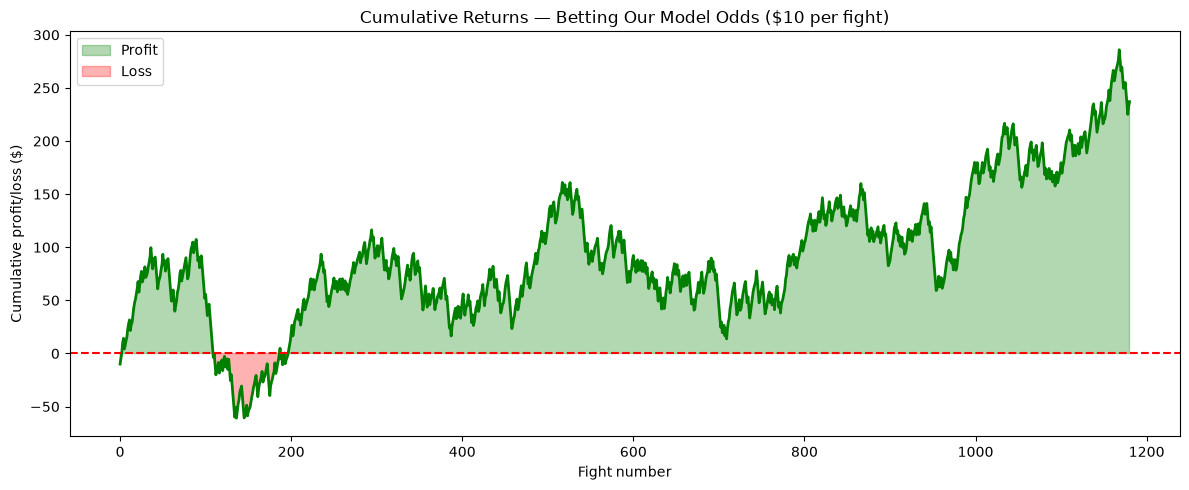

In [9]:
# ── Expected Returns Analysis ─────────────────────────────────

stake = 10  # $ per fight

# Use our test set results
test_returns = pd.DataFrame({
    'red_prob':  red_probs,
    'blue_prob': 1 - red_probs,
    'actual':    y_test.values,
})

# Our model's fair decimal odds = 1 / probability
test_returns['predicted_winner'] = (test_returns['red_prob'] >= 0.5).astype(int)
test_returns['correct']          = (test_returns['predicted_winner'] == test_returns['actual'])

# Odds for the predicted winner (what we'd bet on)
test_returns['our_odds'] = test_returns.apply(
    lambda r: 1 / r['red_prob'] if r['predicted_winner'] == 1 else 1 / r['blue_prob'], axis=1
)

# Return per fight
# If correct: profit = stake × odds - stake
# If wrong:   loss   = -stake
test_returns['return'] = test_returns.apply(
    lambda r: (stake * r['our_odds']) - stake if r['correct'] else -stake, axis=1
)

# Cumulative returns over time
test_returns['cumulative'] = test_returns['return'].cumsum()

# ── Summary Stats ─────────────────────────────────────────────
total_fights  = len(test_returns)
total_staked  = total_fights * stake
total_return  = test_returns['return'].sum()
roi           = (total_return / total_staked) * 100
avg_per_fight = test_returns['return'].mean()
wins          = test_returns['correct'].sum()

print(f"{'='*45}")
print(f"  Expected Returns Analysis")
print(f"{'='*45}")
print(f"  Stake per fight:   ${stake}")
print(f"  Total fights:      {total_fights}")
print(f"  Total staked:      ${total_staked:,.2f}")
print(f"  Correct picks:     {wins}/{total_fights} ({wins/total_fights:.1%})")
print(f"  Total return:      ${total_return:,.2f}")
print(f"  Net profit/loss:   ${total_return - 0:,.2f}")
print(f"  ROI:               {roi:.1f}%")
print(f"  Avg per fight:     ${avg_per_fight:.2f}")
print(f"{'='*45}")

# ── Plot cumulative returns ────────────────────────────────────
plt.figure(figsize=(12, 5))
plt.plot(test_returns['cumulative'], color='green', linewidth=2)
plt.axhline(y=0, color='red', linestyle='--', linewidth=1.5)
plt.fill_between(range(len(test_returns)), 
                 test_returns['cumulative'], 
                 0,
                 where=test_returns['cumulative'] >= 0,
                 alpha=0.3, color='green', label='Profit')
plt.fill_between(range(len(test_returns)),
                 test_returns['cumulative'],
                 0,
                 where=test_returns['cumulative'] < 0,
                 alpha=0.3, color='red', label='Loss')
plt.title('Cumulative Returns — Betting Our Model Odds ($10 per fight)')
plt.xlabel('Fight number')
plt.ylabel('Cumulative profit/loss ($)')
plt.legend()
plt.tight_layout()
plt.show()

  Model Comparison: Logistic Regression vs Random Forest
  Metric                Log Regression   Random Forest
  --------------------------------------------------
  Accuracy                      68.9%          67.4%
  Log Loss                      0.6078          0.6053
  Brier Score                   0.2092          0.2085

  Confidence Bands — Logistic Regression
  Band           Fights   Win Rate
  --------------------------------
  50-60%            260      60.4%
  60-70%            417      63.8%
  70-80%            401      78.3%
  80-90%            102      74.5%
  90-100%             1     100.0%

  Confidence Bands — Random Forest
  Band           Fights   Win Rate
  --------------------------------
  50-60%            263      50.6%
  60-70%            441      66.4%
  70-80%            346      76.0%
  80-90%            130      81.5%
  90-100%             1     100.0%


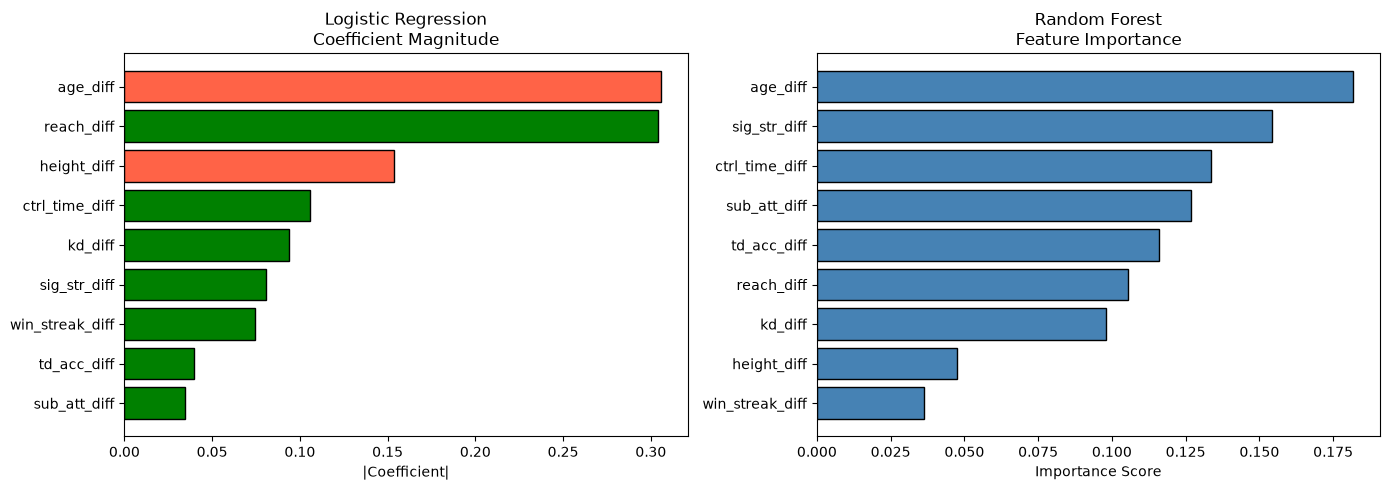

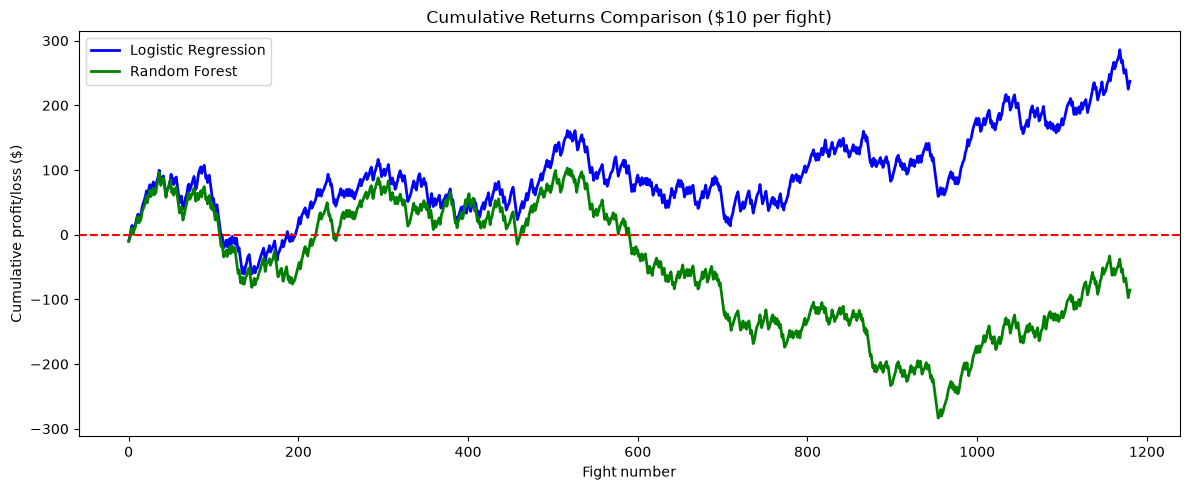

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, log_loss, brier_score_loss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ── Step 1: Train Random Forest ───────────────────────────────
rf_model = RandomForestClassifier(
    n_estimators=500,    # 500 trees
    max_depth=10,        # max depth per tree — prevents overfitting
    min_samples_leaf=20, # each leaf needs at least 20 fights — prevents overfitting
    random_state=42
)
rf_model.fit(X_train_s, y_train)

# ── Step 2: Get predictions & probabilities ───────────────────
rf_preds  = rf_model.predict(X_test_s)
rf_probs  = rf_model.predict_proba(X_test_s)
rf_red    = rf_probs[:, 1]

lr_preds  = model.predict(X_test_s)
lr_probs  = model.predict_proba(X_test_s)
lr_red    = lr_probs[:, 1]

# ── Step 3: Head to head comparison ──────────────────────────
print(f"{'='*55}")
print(f"  Model Comparison: Logistic Regression vs Random Forest")
print(f"{'='*55}")
print(f"  {'Metric':<20} {'Log Regression':>15} {'Random Forest':>15}")
print(f"  {'-'*50}")
print(f"  {'Accuracy':<20} {accuracy_score(y_test, lr_preds):>14.1%} {accuracy_score(y_test, rf_preds):>14.1%}")
print(f"  {'Log Loss':<20} {log_loss(y_test, lr_probs):>15.4f} {log_loss(y_test, rf_probs):>15.4f}")
print(f"  {'Brier Score':<20} {brier_score_loss(y_test, lr_red):>15.4f} {brier_score_loss(y_test, rf_red):>15.4f}")
print(f"{'='*55}")

# ── Step 4: Confidence band comparison ───────────────────────
def confidence_bands(probs, actuals, label):
    df = pd.DataFrame({'prob': probs, 'actual': actuals})
    df['correct']    = (df['prob'].round() == df['actual'])
    df['confidence'] = df['prob'].apply(lambda p: max(p, 1-p))
    bins   = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    labels = ['50-60%', '60-70%', '70-80%', '80-90%', '90-100%']
    df['band'] = pd.cut(df['confidence'], bins=bins, labels=labels)
    summary = df.groupby('band', observed=True).agg(
        Fights  = ('correct', 'count'),
        WinRate = ('correct', 'mean')
    )
    summary['WinRate'] = (summary['WinRate'] * 100).round(1)
    print(f"\n  Confidence Bands — {label}")
    print(f"  {'Band':<12} {'Fights':>8} {'Win Rate':>10}")
    print(f"  {'-'*32}")
    for band, row in summary.iterrows():
        print(f"  {str(band):<12} {int(row['Fights']):>8} {row['WinRate']:>9.1f}%")

confidence_bands(lr_red, y_test.values, 'Logistic Regression')
confidence_bands(rf_red, y_test.values, 'Random Forest')

# ── Step 5: Feature importance ────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Logistic regression coefficients
coef_df = pd.DataFrame({
    'Feature':     feature_cols,
    'Value':       np.abs(model.coef_[0])
}).sort_values('Value')
colors = ['green' if c > 0 else 'tomato' for c in model.coef_[0][
    [feature_cols.index(f) for f in coef_df['Feature']]
]]
axes[0].barh(coef_df['Feature'], coef_df['Value'], color=colors, edgecolor='black')
axes[0].set_title('Logistic Regression\nCoefficient Magnitude')
axes[0].set_xlabel('|Coefficient|')

# Random forest feature importance
imp_df = pd.DataFrame({
    'Feature':    feature_cols,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance')
axes[1].barh(imp_df['Feature'], imp_df['Importance'], color='steelblue', edgecolor='black')
axes[1].set_title('Random Forest\nFeature Importance')
axes[1].set_xlabel('Importance Score')

plt.tight_layout()
plt.show()

# ── Step 6: Cumulative returns comparison ─────────────────────
stake = 10

def cumulative_returns(probs, actuals, stake):
    df = pd.DataFrame({'prob': probs, 'actual': actuals})
    df['predicted'] = (df['prob'] >= 0.5).astype(int)
    df['correct']   = (df['predicted'] == df['actual'])
    df['odds']      = df.apply(
        lambda r: 1/r['prob'] if r['predicted']==1 else 1/(1-r['prob']), axis=1
    )
    df['return']     = df.apply(
        lambda r: (stake * r['odds']) - stake if r['correct'] else -stake, axis=1
    )
    return df['return'].cumsum()

lr_cum = cumulative_returns(lr_red, y_test.values, stake)
rf_cum = cumulative_returns(rf_red, y_test.values, stake)

plt.figure(figsize=(12, 5))
plt.plot(lr_cum, color='blue',  linewidth=2, label='Logistic Regression')
plt.plot(rf_cum, color='green', linewidth=2, label='Random Forest')
plt.axhline(y=0, color='red', linestyle='--', linewidth=1.5)
plt.title('Cumulative Returns Comparison ($10 per fight)')
plt.xlabel('Fight number')
plt.ylabel('Cumulative profit/loss ($)')
plt.legend()
plt.tight_layout()
plt.show()

  Full Model Comparison
  Metric                         LR           RF       Hybrid
  --------------------------------------------------------
  Accuracy                   68.9%       67.4%       68.9%
  Log Loss                   0.6078       0.6053       0.6064
  Brier Score                0.2092       0.2085       0.2087

  Confidence Bands Comparison
  Band        LR Fights  LR Win%  RF Win%  Hybrid Win%
  ----------------------------------------------------
  50-60%            260    60.4%    50.6%        60.4%
  60-70%            417    63.8%    66.4%        64.0%
  70-80%            401    78.3%    76.0%        76.9%
  80-90%            102    74.5%    81.5%        81.0%
  90-100%             1   100.0%   100.0%       100.0%


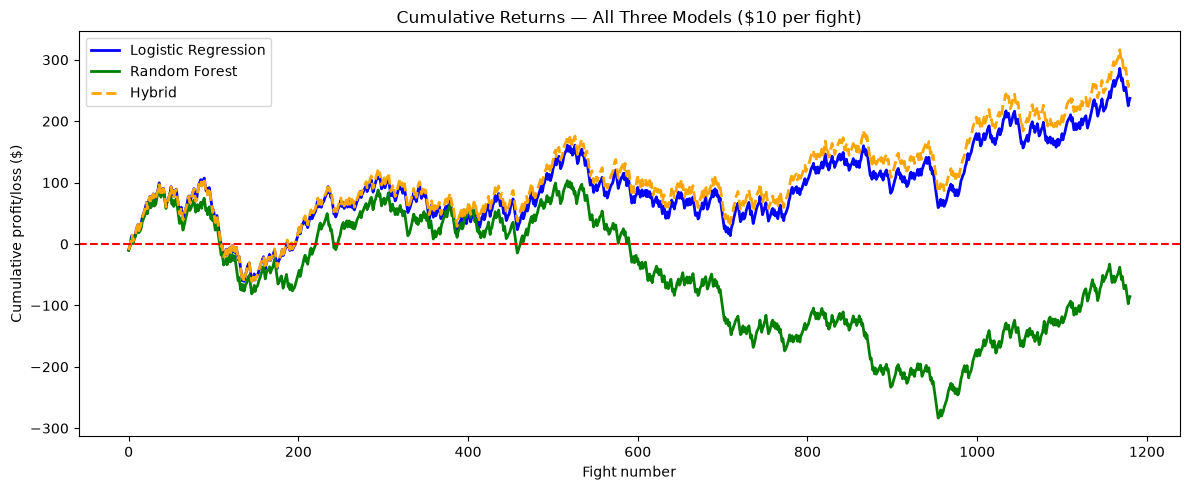


  Hybrid switched to Random Forest on 103/1181 fights (8.7%)
  Logistic Regression used on remaining 1078 fights (91.3%)


In [11]:
# ── Hybrid Model ──────────────────────────────────────────────

# ── Step 1: Get both models' probabilities ────────────────────
lr_probs_full = model.predict_proba(X_test_s)[:, 1]
rf_probs_full = rf_model.predict_proba(X_test_s)[:, 1]

# ── Step 2: Hybrid logic ──────────────────────────────────────
def hybrid_predict(lr_prob, rf_prob, threshold=0.80):
    lr_confidence = max(lr_prob, 1 - lr_prob)
    if lr_confidence >= threshold:
        return rf_prob  # RF better calibrated above 80%
    else:
        return lr_prob  # LR better below 80%

hybrid_probs = np.array([
    hybrid_predict(lr, rf) 
    for lr, rf in zip(lr_probs_full, rf_probs_full)
])

hybrid_preds = (hybrid_probs >= 0.5).astype(int)

# ── Step 3: Full comparison all three models ──────────────────
print(f"{'='*60}")
print(f"  Full Model Comparison")
print(f"{'='*60}")
print(f"  {'Metric':<20} {'LR':>12} {'RF':>12} {'Hybrid':>12}")
print(f"  {'-'*56}")
print(f"  {'Accuracy':<20} {accuracy_score(y_test, lr_preds):>11.1%} {accuracy_score(y_test, rf_preds):>11.1%} {accuracy_score(y_test, hybrid_preds):>11.1%}")
print(f"  {'Log Loss':<20} {log_loss(y_test, lr_probs_full):>12.4f} {log_loss(y_test, rf_probs_full):>12.4f} {log_loss(y_test, hybrid_probs):>12.4f}")
print(f"  {'Brier Score':<20} {brier_score_loss(y_test, lr_probs_full):>12.4f} {brier_score_loss(y_test, rf_probs_full):>12.4f} {brier_score_loss(y_test, hybrid_probs):>12.4f}")
print(f"{'='*60}")

# ── Step 4: Confidence bands all three ───────────────────────
def confidence_bands_df(probs, actuals):
    df = pd.DataFrame({'prob': probs, 'actual': actuals})
    df['correct']    = (df['prob'].round() == df['actual'])
    df['confidence'] = df['prob'].apply(lambda p: max(p, 1-p))
    df['brier']      = (df['prob'] - df['actual']) ** 2
    bins   = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    labels = ['50-60%', '60-70%', '70-80%', '80-90%', '90-100%']
    df['band'] = pd.cut(df['confidence'], bins=bins, labels=labels)
    return df.groupby('band', observed=True).agg(
        Fights  = ('correct', 'count'),
        WinRate = ('correct', 'mean'),
        Penalty = ('brier',   'mean')
    )

lr_bands  = confidence_bands_df(lr_probs_full,  y_test.values)
rf_bands  = confidence_bands_df(rf_probs_full,  y_test.values)
hyb_bands = confidence_bands_df(hybrid_probs,   y_test.values)

print(f"\n  Confidence Bands Comparison")
print(f"  {'Band':<10} {'LR Fights':>10} {'LR Win%':>8} {'RF Win%':>8} {'Hybrid Win%':>12}")
print(f"  {'-'*52}")
for band in lr_bands.index:
    lr_r  = lr_bands.loc[band,  'WinRate'] * 100
    rf_r  = rf_bands.loc[band,  'WinRate'] * 100
    hy_r  = hyb_bands.loc[band, 'WinRate'] * 100
    fights= int(lr_bands.loc[band, 'Fights'])
    print(f"  {str(band):<10} {fights:>10} {lr_r:>7.1f}% {rf_r:>7.1f}% {hy_r:>11.1f}%")

# ── Step 5: Cumulative returns all three ─────────────────────
stake = 10

def cum_returns(probs, actuals, stake):
    df = pd.DataFrame({'prob': probs, 'actual': actuals})
    df['predicted'] = (df['prob'] >= 0.5).astype(int)
    df['correct']   = (df['predicted'] == df['actual'])
    df['odds']      = df.apply(
        lambda r: 1/r['prob'] if r['predicted']==1 else 1/(1-r['prob']), axis=1
    )
    df['return'] = df.apply(
        lambda r: (stake * r['odds']) - stake if r['correct'] else -stake, axis=1
    )
    return df['return'].cumsum()

lr_cum  = cum_returns(lr_probs_full,  y_test.values, stake)
rf_cum  = cum_returns(rf_probs_full,  y_test.values, stake)
hyb_cum = cum_returns(hybrid_probs,   y_test.values, stake)

plt.figure(figsize=(12, 5))
plt.plot(lr_cum,  color='blue',   linewidth=2, label='Logistic Regression')
plt.plot(rf_cum,  color='green',  linewidth=2, label='Random Forest')
plt.plot(hyb_cum, color='orange', linewidth=2, label='Hybrid', linestyle='--')
plt.axhline(y=0, color='red', linestyle='--', linewidth=1.5)
plt.title('Cumulative Returns — All Three Models ($10 per fight)')
plt.xlabel('Fight number')
plt.ylabel('Cumulative profit/loss ($)')
plt.legend()
plt.tight_layout()
plt.show()

# ── Step 6: Where did hybrid switch to RF? ────────────────────
switches = sum(1 for lr, rf in zip(lr_probs_full, rf_probs_full)
               if max(lr, 1-lr) >= 0.80)
print(f"\n  Hybrid switched to Random Forest on {switches}/{len(y_test)} fights ({switches/len(y_test):.1%})")
print(f"  Logistic Regression used on remaining {len(y_test)-switches} fights ({(len(y_test)-switches)/len(y_test):.1%})")

  Out of Sample Dataset
  Total fights:    2346
  Usable fights:   2344
  Date range:      2022-01-15 to 2026-07-11
  Red win rate:    55.4%
  kd_diff:         filled with 0 (scraper limitation)
  ctrl_time_diff:  filled with 0 (scraper limitation)

  Model Comparison — Out of Sample (2022-2026)
  Metric                       LR         RF     Hybrid
  -------------------------------------------------------
  Accuracy                 58.1%     56.9%     58.1%
  Log Loss                 0.6728     0.6752     0.6729
  Brier Score              0.2402     0.2412     0.2403

  Confidence Bands — Logistic Regression
  Band           Fights   Win Rate    Avg Brier
  ---------------------------------------------
  50-60%            560     46.1%       0.2607
  60-70%            874     54.0%       0.2571
  70-80%            755     66.5%       0.2272
  80-90%            154     83.8%       0.1350
  90-100%             1    100.0%       0.0088

  Confidence Bands — Random Forest
  Band         

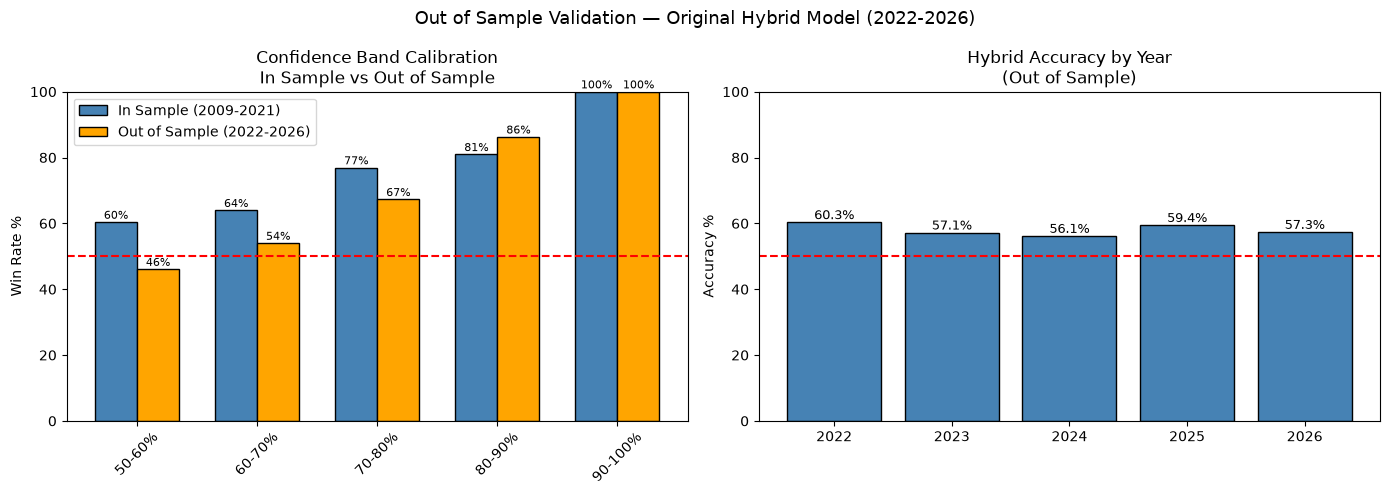

In [12]:
# ── Out of Sample Validation — Original Hybrid Model ─────────
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, log_loss, brier_score_loss

# ── Step 1: Load scraped data ─────────────────────────────────
oos = pd.read_csv('ufc_2022_2025_preprocessed.csv')
oos = oos.replace('None', np.nan)

# All 9 feature cols — same as original model
feature_cols = [
    'reach_diff', 'height_diff', 'age_diff', 'sig_str_diff',
    'kd_diff', 'td_acc_diff', 'sub_att_diff', 
    'win_streak_diff', 'ctrl_time_diff'
]

for col in feature_cols:
    oos[col] = pd.to_numeric(oos[col], errors='coerce')

# Fill missing kd_diff and ctrl_time_diff with 0 — neutral assumption
oos['kd_diff']       = oos['kd_diff'].fillna(0)
oos['ctrl_time_diff']= oos['ctrl_time_diff'].fillna(0)

oos['result']  = (oos['winner'] == 'red').astype(int)
oos_clean      = oos[feature_cols + ['result', 'red_name', 'blue_name', 'date']].dropna()

print(f"{'='*55}")
print(f"  Out of Sample Dataset")
print(f"{'='*55}")
print(f"  Total fights:    {len(oos)}")
print(f"  Usable fights:   {len(oos_clean)}")
print(f"  Date range:      {oos_clean['date'].min()} to {oos_clean['date'].max()}")
print(f"  Red win rate:    {oos_clean['result'].mean():.1%}")
print(f"  kd_diff:         filled with 0 (scraper limitation)")
print(f"  ctrl_time_diff:  filled with 0 (scraper limitation)")
print(f"{'='*55}")

# ── Step 2: Scale using EXACT same scaler from training ───────
X_oos = scaler.transform(oos_clean[feature_cols])
y_oos = oos_clean['result'].values

# ── Step 3: Apply EXACT same models — no retraining ───────────
lr_p_oos  = model.predict_proba(X_oos)[:, 1]
rf_p_oos  = rf_model.predict_proba(X_oos)[:, 1]

# Exact same hybrid logic as before
hyb_p_oos = np.array([
    rf_p if max(lr_p, 1-lr_p) >= 0.80 else lr_p
    for lr_p, rf_p in zip(lr_p_oos, rf_p_oos)
])

lr_pred_oos  = (lr_p_oos  >= 0.5).astype(int)
rf_pred_oos  = (rf_p_oos  >= 0.5).astype(int)
hyb_pred_oos = (hyb_p_oos >= 0.5).astype(int)

# ── Step 4: Results ───────────────────────────────────────────
print(f"\n{'='*60}")
print(f"  Model Comparison — Out of Sample (2022-2026)")
print(f"{'='*60}")
print(f"  {'Metric':<20} {'LR':>10} {'RF':>10} {'Hybrid':>10}")
print(f"  {'-'*55}")
print(f"  {'Accuracy':<20} {accuracy_score(y_oos,lr_pred_oos):>9.1%} {accuracy_score(y_oos,rf_pred_oos):>9.1%} {accuracy_score(y_oos,hyb_pred_oos):>9.1%}")
print(f"  {'Log Loss':<20} {log_loss(y_oos,lr_p_oos):>10.4f} {log_loss(y_oos,rf_p_oos):>10.4f} {log_loss(y_oos,hyb_p_oos):>10.4f}")
print(f"  {'Brier Score':<20} {brier_score_loss(y_oos,lr_p_oos):>10.4f} {brier_score_loss(y_oos,rf_p_oos):>10.4f} {brier_score_loss(y_oos,hyb_p_oos):>10.4f}")
print(f"{'='*60}")

# ── Step 5: Confidence bands ──────────────────────────────────
def conf_bands(probs, actuals, label):
    df_e = pd.DataFrame({'prob': probs, 'actual': actuals})
    df_e['correct']    = (df_e['prob'].round() == df_e['actual'])
    df_e['confidence'] = df_e['prob'].apply(lambda p: max(p, 1-p))
    df_e['brier']      = (df_e['prob'] - df_e['actual']) ** 2
    bins   = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    labels = ['50-60%', '60-70%', '70-80%', '80-90%', '90-100%']
    df_e['band'] = pd.cut(df_e['confidence'], bins=bins, labels=labels)
    summary = df_e.groupby('band', observed=True).agg(
        Fights   = ('correct', 'count'),
        WinRate  = ('correct', 'mean'),
        AvgBrier = ('brier',   'mean')
    )
    print(f"\n  Confidence Bands — {label}")
    print(f"  {'Band':<12} {'Fights':>8} {'Win Rate':>10} {'Avg Brier':>12}")
    print(f"  {'-'*45}")
    for band, row in summary.iterrows():
        print(f"  {str(band):<12} {int(row['Fights']):>8} {row['WinRate']:>9.1%} {row['AvgBrier']:>12.4f}")

conf_bands(lr_p_oos,  y_oos, 'Logistic Regression')
conf_bands(rf_p_oos,  y_oos, 'Random Forest')
conf_bands(hyb_p_oos, y_oos, 'Hybrid')

# ── Step 6: Generalisation check ─────────────────────────────
in_sample_acc = accuracy_score(y_test, (hybrid_probs >= 0.5).astype(int))
oos_acc       = accuracy_score(y_oos, hyb_pred_oos)
degradation   = in_sample_acc - oos_acc

print(f"\n{'='*55}")
print(f"  Generalisation Check — Hybrid Model")
print(f"{'='*55}")
print(f"  In-sample accuracy:      {in_sample_acc:.1%}")
print(f"  Out-of-sample accuracy:  {oos_acc:.1%}")
print(f"  Degradation:             {degradation:+.1%}")
print(f"  Verdict: {'Minimal overfitting — model generalises well' if abs(degradation) < 0.03 else 'Some degradation detected'}")
print(f"{'='*55}")

# ── Step 7: Accuracy by year ──────────────────────────────────
oos_clean2            = oos_clean.copy()
oos_clean2['year']    = pd.to_datetime(oos_clean2['date']).dt.year
oos_clean2['correct'] = (hyb_pred_oos == y_oos)
year_acc = oos_clean2.groupby('year')['correct'].mean() * 100

print(f"\n  Accuracy by Year — Hybrid Model")
print(f"  {'Year':>6} {'Fights':>8} {'Accuracy':>10}")
print(f"  {'-'*28}")
for year, acc in year_acc.items():
    n = len(oos_clean2[oos_clean2['year'] == year])
    print(f"  {year:>6} {n:>8} {acc:>9.1f}%")

# ── Step 8: Plot ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Out of Sample Validation — Original Hybrid Model (2022-2026)', fontsize=13)

bands = ['50-60%', '60-70%', '70-80%', '80-90%', '90-100%']

def get_band_acc(probs, actuals):
    df_e = pd.DataFrame({'prob': probs, 'actual': actuals})
    df_e['correct']    = (df_e['prob'].round() == df_e['actual'])
    df_e['confidence'] = df_e['prob'].apply(lambda p: max(p, 1-p))
    df_e['band']       = pd.cut(df_e['confidence'], bins=[0.5,0.6,0.7,0.8,0.9,1.0], labels=bands)
    return df_e.groupby('band', observed=True)['correct'].mean().values * 100

in_s  = get_band_acc(hybrid_probs,  y_test.values)
oos_b = get_band_acc(hyb_p_oos,     y_oos)

x = np.arange(len(bands))
w = 0.35
axes[0].bar(x-w/2, in_s,  w, label='In Sample (2009-2021)',     color='steelblue', edgecolor='black')
axes[0].bar(x+w/2, oos_b, w, label='Out of Sample (2022-2026)', color='orange',    edgecolor='black')
axes[0].axhline(50, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title('Confidence Band Calibration\nIn Sample vs Out of Sample')
axes[0].set_xticks(x)
axes[0].set_xticklabels(bands, rotation=45)
axes[0].set_ylabel('Win Rate %')
axes[0].set_ylim(0, 100)
axes[0].legend()
for i, (a, b) in enumerate(zip(in_s, oos_b)):
    if not np.isnan(a): axes[0].text(i-w/2, a+1, f'{a:.0f}%', ha='center', fontsize=8)
    if not np.isnan(b): axes[0].text(i+w/2, b+1, f'{b:.0f}%', ha='center', fontsize=8)

axes[1].bar(year_acc.index.astype(str), year_acc.values, color='steelblue', edgecolor='black')
axes[1].axhline(50, color='red', linestyle='--', linewidth=1.5)
axes[1].set_title('Hybrid Accuracy by Year\n(Out of Sample)')
axes[1].set_ylabel('Accuracy %')
axes[1].set_ylim(0, 100)
for i, (yr, val) in enumerate(year_acc.items()):
    axes[1].text(i, val+1, f'{val:.1f}%', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

In [13]:
# ── 7 Feature Model — consistent in and out of sample ────────
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, log_loss, brier_score_loss
import numpy as np

df = preprocessed.copy()

features_7 = {
    'reach_diff':      ('R_Reach_cms',          'B_Reach_cms'),
    'height_diff':     ('R_Height_cms',         'B_Height_cms'),
    'age_diff':        ('R_age',                'B_age'),
    'sig_str_diff':    ('R_avg_SIG_STR_pct',    'B_avg_SIG_STR_pct'),
    'td_acc_diff':     ('R_avg_TD_pct',         'B_avg_TD_pct'),
    'sub_att_diff':    ('R_avg_SUB_ATT',        'B_avg_SUB_ATT'),
    'win_streak_diff': ('R_current_win_streak', 'B_current_win_streak'),
}

feature_cols_7 = list(features_7.keys())

for col_name, (r_col, b_col) in features_7.items():
    df[col_name] = df[r_col] - df[b_col]

df['result']  = (df['Winner'] == 'Red').astype(int)
df_model      = df[feature_cols_7 + ['result']].dropna()

X7 = df_model[feature_cols_7]
y7 = df_model['result']

# ── Train/test split ──────────────────────────────────────────
X7_train, X7_test, y7_train, y7_test = train_test_split(
    X7, y7, test_size=0.2, random_state=42
)

scaler7   = StandardScaler()
X7_train_s = scaler7.fit_transform(X7_train)
X7_test_s  = scaler7.transform(X7_test)

# ── Train models ──────────────────────────────────────────────
lr7 = LogisticRegression(random_state=42)
lr7.fit(X7_train_s, y7_train)

rf7 = RandomForestClassifier(n_estimators=500, max_depth=10, min_samples_leaf=20, random_state=42)
rf7.fit(X7_train_s, y7_train)

# ── Hybrid ────────────────────────────────────────────────────
lr7_probs  = lr7.predict_proba(X7_test_s)[:, 1]
rf7_probs  = rf7.predict_proba(X7_test_s)[:, 1]

hybrid7_probs = np.array([
    rf_p if max(lr_p, 1-lr_p) >= 0.80 else lr_p
    for lr_p, rf_p in zip(lr7_probs, rf7_probs)
])

lr7_preds     = (lr7_probs     >= 0.5).astype(int)
rf7_preds     = (rf7_probs     >= 0.5).astype(int)
hybrid7_preds = (hybrid7_probs >= 0.5).astype(int)

# ── In sample results ─────────────────────────────────────────
print(f"{'='*60}")
print(f"  7-Feature Model — In Sample Results")
print(f"{'='*60}")
print(f"  {'Metric':<20} {'LR':>10} {'RF':>10} {'Hybrid':>10}")
print(f"  {'-'*55}")
print(f"  {'Accuracy':<20} {accuracy_score(y7_test,lr7_preds):>9.1%} {accuracy_score(y7_test,rf7_preds):>9.1%} {accuracy_score(y7_test,hybrid7_preds):>9.1%}")
print(f"  {'Log Loss':<20} {log_loss(y7_test,lr7_probs):>10.4f} {log_loss(y7_test,rf7_probs):>10.4f} {log_loss(y7_test,hybrid7_probs):>10.4f}")
print(f"  {'Brier Score':<20} {brier_score_loss(y7_test,lr7_probs):>10.4f} {brier_score_loss(y7_test,rf7_probs):>10.4f} {brier_score_loss(y7_test,hybrid7_probs):>10.4f}")
print(f"{'='*60}")

# ── Coefficients ──────────────────────────────────────────────
coef7_df = pd.DataFrame({
    'Feature':     feature_cols_7,
    'Coefficient': lr7.coef_[0]
}).sort_values('Coefficient', ascending=False)

print(f"\n  7-Feature Logistic Regression Coefficients:")
print(f"  {'-'*35}")
print(coef7_df.to_string(index=False))

# ── Now apply to OOS ──────────────────────────────────────────
oos = pd.read_csv('ufc_2022_2025_preprocessed.csv')
oos = oos.replace('None', np.nan)

for col in feature_cols_7:
    oos[col] = pd.to_numeric(oos[col], errors='coerce')

oos['result']  = (oos['winner'] == 'red').astype(int)
oos_clean      = oos[feature_cols_7 + ['result', 'red_name', 'blue_name', 'date']].dropna()

print(f"\n  OOS fights available: {len(oos_clean)}")

X7_oos = scaler7.transform(oos_clean[feature_cols_7])
y7_oos = oos_clean['result'].values

lr7_oos_probs  = lr7.predict_proba(X7_oos)[:, 1]
rf7_oos_probs  = rf7.predict_proba(X7_oos)[:, 1]

hybrid7_oos_probs = np.array([
    rf_p if max(lr_p, 1-lr_p) >= 0.80 else lr_p
    for lr_p, rf_p in zip(lr7_oos_probs, rf7_oos_probs)
])

hybrid7_oos_preds = (hybrid7_oos_probs >= 0.5).astype(int)
lr7_oos_preds     = (lr7_oos_probs     >= 0.5).astype(int)
rf7_oos_preds     = (rf7_oos_probs     >= 0.5).astype(int)

# ── OOS results ───────────────────────────────────────────────
print(f"\n{'='*60}")
print(f"  7-Feature Model — Out of Sample Results (2022-2026)")
print(f"{'='*60}")
print(f"  {'Metric':<20} {'LR':>10} {'RF':>10} {'Hybrid':>10}")
print(f"  {'-'*55}")
print(f"  {'Accuracy':<20} {accuracy_score(y7_oos,lr7_oos_preds):>9.1%} {accuracy_score(y7_oos,rf7_oos_preds):>9.1%} {accuracy_score(y7_oos,hybrid7_oos_preds):>9.1%}")
print(f"  {'Log Loss':<20} {log_loss(y7_oos,lr7_oos_probs):>10.4f} {log_loss(y7_oos,rf7_oos_probs):>10.4f} {log_loss(y7_oos,hybrid7_oos_probs):>10.4f}")
print(f"  {'Brier Score':<20} {brier_score_loss(y7_oos,lr7_oos_probs):>10.4f} {brier_score_loss(y7_oos,rf7_oos_probs):>10.4f} {brier_score_loss(y7_oos,hybrid7_oos_probs):>10.4f}")
print(f"{'='*60}")

# ── Generalisation check ──────────────────────────────────────
in_acc  = accuracy_score(y7_test,  hybrid7_preds)
oos_acc = accuracy_score(y7_oos,   hybrid7_oos_preds)
deg     = in_acc - oos_acc

print(f"\n{'='*55}")
print(f"  Generalisation Check — 7-Feature Hybrid")
print(f"{'='*55}")
print(f"  In-sample accuracy:      {in_acc:.1%}")
print(f"  Out-of-sample accuracy:  {oos_acc:.1%}")
print(f"  Degradation:             {deg:+.1%}")
print(f"  Verdict: {'Minimal overfitting' if abs(deg) < 0.03 else 'Some degradation detected'}")
print(f"{'='*55}")

# ── Confidence bands ──────────────────────────────────────────
def conf_bands(probs, actuals, label):
    df_e = pd.DataFrame({'prob': probs, 'actual': actuals})
    df_e['correct']    = (df_e['prob'].round() == df_e['actual'])
    df_e['confidence'] = df_e['prob'].apply(lambda p: max(p, 1-p))
    bins   = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    labels = ['50-60%', '60-70%', '70-80%', '80-90%', '90-100%']
    df_e['band'] = pd.cut(df_e['confidence'], bins=bins, labels=labels)
    summary = df_e.groupby('band', observed=True).agg(
        Fights  = ('correct', 'count'),
        WinRate = ('correct', 'mean'),
    )
    print(f"\n  Confidence Bands — {label}")
    print(f"  {'Band':<12} {'Fights':>8} {'Win Rate':>10}")
    print(f"  {'-'*32}")
    for band, row in summary.iterrows():
        print(f"  {str(band):<12} {int(row['Fights']):>8} {row['WinRate']:>9.1%}")

conf_bands(hybrid7_probs,     y7_test.values, 'Hybrid In Sample')
conf_bands(hybrid7_oos_probs, y7_oos,         'Hybrid Out of Sample')

  7-Feature Model — In Sample Results
  Metric                       LR         RF     Hybrid
  -------------------------------------------------------
  Accuracy                 68.5%     68.1%     68.5%
  Log Loss                 0.6043     0.6055     0.6034
  Brier Score              0.2077     0.2085     0.2074

  7-Feature Logistic Regression Coefficients:
  -----------------------------------
        Feature  Coefficient
     reach_diff     0.306256
   sig_str_diff     0.104080
win_streak_diff     0.082420
    td_acc_diff     0.067054
   sub_att_diff     0.034840
    height_diff    -0.160952
       age_diff    -0.312573

  OOS fights available: 2344

  7-Feature Model — Out of Sample Results (2022-2026)
  Metric                       LR         RF     Hybrid
  -------------------------------------------------------
  Accuracy                 58.3%     57.1%     58.3%
  Log Loss                 0.6694     0.6707     0.6706
  Brier Score              0.2387     0.2393     0.2391

 

In [14]:
# Find row index where 2018 starts in raw fight data
fight_data['date_parsed'] = pd.to_datetime(fight_data['date'], format='%B %d, %Y')

# Count fights from 2019 onwards (newest end)
post_2018 = fight_data[fight_data['date_parsed'].dt.year >= 2019]
pre_2019  = fight_data[fight_data['date_parsed'].dt.year <  2019]

print(f"Fights 2019-2021 (test set):  {len(post_2018)}")
print(f"Fights up to 2018 (train set): {len(pre_2019)}")
print(f"Total: {len(fight_data)}")

print(f"\nFirst post-2018 fight: {post_2018.iloc[-1]['date']} (row {post_2018.index[-1]})")
print(f"Last post-2018 fight:  {post_2018.iloc[0]['date']}  (row {post_2018.index[0]})")

split_row = len(post_2018)
print(f"\nSplit row index: {split_row}")
print(f"Preprocessed has {len(preprocessed)} rows")
print(f"\nUsing first {split_row} rows of preprocessed as TEST (2019-2021)")
print(f"Using remaining {len(preprocessed) - split_row} rows as TRAIN (up to 2018)")

Fights 2019-2021 (test set):  1088
Fights up to 2018 (train set): 4924
Total: 6012

First post-2018 fight: January 19, 2019 (row 1087)
Last post-2018 fight:  March 20, 2021  (row 0)

Split row index: 1088
Preprocessed has 5902 rows

Using first 1088 rows of preprocessed as TEST (2019-2021)
Using remaining 4814 rows as TRAIN (up to 2018)


In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, log_loss, brier_score_loss

# ── Features ──────────────────────────────────────────────────
features_7 = {
    'reach_diff':      ('R_Reach_cms',          'B_Reach_cms'),
    'height_diff':     ('R_Height_cms',         'B_Height_cms'),
    'age_diff':        ('R_age',                'B_age'),
    'sig_str_diff':    ('R_avg_SIG_STR_pct',    'B_avg_SIG_STR_pct'),
    'td_acc_diff':     ('R_avg_TD_pct',         'B_avg_TD_pct'),
    'sub_att_diff':    ('R_avg_SUB_ATT',        'B_avg_SUB_ATT'),
    'win_streak_diff': ('R_current_win_streak', 'B_current_win_streak'),
}
feature_cols_7 = list(features_7.keys())

df = preprocessed.copy()
for col_name, (r_col, b_col) in features_7.items():
    df[col_name] = df[r_col] - df[b_col]
df['result'] = (df['Winner'] == 'Red').astype(int)
df_model     = df[feature_cols_7 + ['result']].dropna().reset_index(drop=True)

print(f"Total preprocessed rows after dropna: {len(df_model)}")

# ── Temporal split using row position ─────────────────────────
split_row = 1088

# Preprocessed is newest first so:
# rows 0-1087     = 2019-2021 (TEST period 1)
# rows 1088+      = up to 2018 (TRAIN)
train_df = df_model.iloc[split_row:].reset_index(drop=True)
test1_df = df_model.iloc[:split_row].reset_index(drop=True)

print(f"\nTrain set (up to 2018):    {len(train_df)} fights")
print(f"Test set 1 (2019-2021):    {len(test1_df)} fights")

X_train = train_df[feature_cols_7]
y_train = train_df['result']
X_test1 = test1_df[feature_cols_7]
y_test1 = test1_df['result']

# ── Scale ─────────────────────────────────────────────────────
scaler7    = StandardScaler()
X_train_s  = scaler7.fit_transform(X_train)
X_test1_s  = scaler7.transform(X_test1)

# ── Train models on pre-2019 data only ───────────────────────
lr7 = LogisticRegression(random_state=42)
lr7.fit(X_train_s, y_train)

rf7 = RandomForestClassifier(n_estimators=500, max_depth=10, min_samples_leaf=20, random_state=42)
rf7.fit(X_train_s, y_train)

def hybrid_probs(lr_p, rf_p):
    return np.array([
        rf if max(lr, 1-lr) >= 0.80 else lr
        for lr, rf in zip(lr_p, rf_p)
    ])

# ── Period 1 results: 2019-2021 ───────────────────────────────
lr_p1  = lr7.predict_proba(X_test1_s)[:, 1]
rf_p1  = rf7.predict_proba(X_test1_s)[:, 1]
hyb_p1 = hybrid_probs(lr_p1, rf_p1)

print(f"\n{'='*65}")
print(f"  Results — Trained on pre-2019, Tested on 2019-2021")
print(f"{'='*65}")
print(f"  {'Metric':<20} {'LR':>10} {'RF':>10} {'Hybrid':>10}")
print(f"  {'-'*55}")
print(f"  {'Accuracy':<20} {accuracy_score(y_test1,(lr_p1>=0.5).astype(int)):>9.1%} {accuracy_score(y_test1,(rf_p1>=0.5).astype(int)):>9.1%} {accuracy_score(y_test1,(hyb_p1>=0.5).astype(int)):>9.1%}")
print(f"  {'Log Loss':<20} {log_loss(y_test1,lr_p1):>10.4f} {log_loss(y_test1,rf_p1):>10.4f} {log_loss(y_test1,hyb_p1):>10.4f}")
print(f"  {'Brier Score':<20} {brier_score_loss(y_test1,lr_p1):>10.4f} {brier_score_loss(y_test1,rf_p1):>10.4f} {brier_score_loss(y_test1,hyb_p1):>10.4f}")
print(f"{'='*65}")

# ── Confidence bands 2019-2021 ────────────────────────────────
def conf_bands(probs, actuals, label):
    df_e = pd.DataFrame({'prob': probs, 'actual': actuals})
    df_e['correct']    = (df_e['prob'].round() == df_e['actual'])
    df_e['confidence'] = df_e['prob'].apply(lambda p: max(p, 1-p))
    bins   = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    labels = ['50-60%', '60-70%', '70-80%', '80-90%', '90-100%']
    df_e['band'] = pd.cut(df_e['confidence'], bins=bins, labels=labels)
    summary = df_e.groupby('band', observed=True).agg(
        Fights  = ('correct', 'count'),
        WinRate = ('correct', 'mean'),
    )
    print(f"\n  Confidence Bands — {label}")
    print(f"  {'Band':<12} {'Fights':>8} {'Win Rate':>10}")
    print(f"  {'-'*32}")
    for band, row in summary.iterrows():
        print(f"  {str(band):<12} {int(row['Fights']):>8} {row['WinRate']:>9.1%}")

conf_bands(hyb_p1, y_test1.values, 'Hybrid — 2019-2021')

# ── Period 2: OOS 2022-2026 ───────────────────────────────────
oos = pd.read_csv('ufc_2022_2025_preprocessed.csv')
oos = oos.replace('None', np.nan)
for col in feature_cols_7:
    oos[col] = pd.to_numeric(oos[col], errors='coerce')
oos['result'] = (oos['winner'] == 'red').astype(int)
oos_clean     = oos[feature_cols_7 + ['result', 'red_name', 'blue_name', 'date']].dropna()

X_oos   = scaler7.transform(oos_clean[feature_cols_7])
y_oos   = oos_clean['result'].values
lr_p2   = lr7.predict_proba(X_oos)[:, 1]
rf_p2   = rf7.predict_proba(X_oos)[:, 1]
hyb_p2  = hybrid_probs(lr_p2, rf_p2)

print(f"\n{'='*65}")
print(f"  Results — Trained on pre-2019, Tested on 2022-2026 (OOS)")
print(f"{'='*65}")
print(f"  {'Metric':<20} {'LR':>10} {'RF':>10} {'Hybrid':>10}")
print(f"  {'-'*55}")
print(f"  {'Accuracy':<20} {accuracy_score(y_oos,(lr_p2>=0.5).astype(int)):>9.1%} {accuracy_score(y_oos,(rf_p2>=0.5).astype(int)):>9.1%} {accuracy_score(y_oos,(hyb_p2>=0.5).astype(int)):>9.1%}")
print(f"  {'Log Loss':<20} {log_loss(y_oos,lr_p2):>10.4f} {log_loss(y_oos,rf_p2):>10.4f} {log_loss(y_oos,hyb_p2):>10.4f}")
print(f"  {'Brier Score':<20} {brier_score_loss(y_oos,lr_p2):>10.4f} {brier_score_loss(y_oos,rf_p2):>10.4f} {brier_score_loss(y_oos,hyb_p2):>10.4f}")
print(f"{'='*65}")

conf_bands(hyb_p2, y_oos, 'Hybrid — 2022-2026 OOS')

# ── Coefficients ──────────────────────────────────────────────
coef_df = pd.DataFrame({
    'Feature':     feature_cols_7,
    'Coefficient': lr7.coef_[0]
}).sort_values('Coefficient', ascending=False)

print(f"\n  7-Feature Coefficients (trained pre-2019):")
print(f"  {'-'*35}")
print(coef_df.to_string(index=False))

# ── Summary ───────────────────────────────────────────────────
acc_train  = accuracy_score(y_train, (lr7.predict_proba(X_train_s)[:,1]>=0.5).astype(int))
acc_test1  = accuracy_score(y_test1, (hyb_p1>=0.5).astype(int))
acc_oos    = accuracy_score(y_oos,   (hyb_p2>=0.5).astype(int))

print(f"\n{'='*55}")
print(f"  Three Period Summary — Hybrid Model")
print(f"{'='*55}")
print(f"  Train  (pre-2019):   {acc_train:.1%}  ({len(train_df)} fights)")
print(f"  Test 1 (2019-2021):  {acc_test1:.1%}  ({len(test1_df)} fights)")
print(f"  OOS    (2022-2026):  {acc_oos:.1%}  ({len(oos_clean)} fights)")
print(f"{'='*55}")

Total preprocessed rows after dropna: 5902

Train set (up to 2018):    4814 fights
Test set 1 (2019-2021):    1088 fights

  Results — Trained on pre-2019, Tested on 2019-2021
  Metric                       LR         RF     Hybrid
  -------------------------------------------------------
  Accuracy                 58.8%     58.4%     58.8%
  Log Loss                 0.6867     0.6835     0.6848
  Brier Score              0.2454     0.2441     0.2446

  Confidence Bands — Hybrid — 2019-2021
  Band           Fights   Win Rate
  --------------------------------
  50-60%            215     50.2%
  60-70%            359     51.0%
  70-80%            444     66.9%
  80-90%             69     75.4%
  90-100%             1      0.0%

  Results — Trained on pre-2019, Tested on 2022-2026 (OOS)
  Metric                       LR         RF     Hybrid
  -------------------------------------------------------
  Accuracy                 57.8%     58.4%     57.8%
  Log Loss                 0.6815    

In [16]:
# ── Find 2010-2018 rows in raw fight data ─────────────────────
train_period = fight_data[
    (fight_data['date_parsed'].dt.year >= 2010) &
    (fight_data['date_parsed'].dt.year <= 2018)
]
pre_2010 = fight_data[fight_data['date_parsed'].dt.year < 2010]

print(f"Fights 2010-2018: {len(train_period)}")
print(f"Fights pre-2010:  {len(pre_2010)}")
print(f"Fights 2019-2021: {len(post_2018)}")

# Row positions in raw fight data (newest first)
# post_2018 = rows 0-1087    (2019-2021)
# 2010-2018 = rows 1088-????
# pre-2010  = rows ????-6011

post2018_end   = len(post_2018)           # 1088
train_end      = post2018_end + len(train_period)
print(f"\nRow ranges in raw fight data:")
print(f"  2019-2021: rows 0 to {post2018_end-1}")
print(f"  2010-2018: rows {post2018_end} to {train_end-1}")
print(f"  pre-2010:  rows {train_end} to {len(fight_data)-1}")

print(f"\nApplying to preprocessed ({len(df_model)} rows after dropna):")
print(f"  Test 1  (2019-2021): rows 0 to {post2018_end-1}")
print(f"  Train   (2010-2018): rows {post2018_end} to {min(train_end-1, len(df_model)-1)}")
print(f"  Dropped (pre-2010):  rows {train_end} onwards")

Fights 2010-2018: 3680
Fights pre-2010:  1244
Fights 2019-2021: 1088

Row ranges in raw fight data:
  2019-2021: rows 0 to 1087
  2010-2018: rows 1088 to 4767
  pre-2010:  rows 4768 to 6011

Applying to preprocessed (5902 rows after dropna):
  Test 1  (2019-2021): rows 0 to 1087
  Train   (2010-2018): rows 1088 to 4767
  Dropped (pre-2010):  rows 4768 onwards


In [17]:
# ── 2010-2018 only model ──────────────────────────────────────

# Split preprocessed by row position
test1_df  = df_model.iloc[0:1088].reset_index(drop=True)      # 2019-2021
train_df  = df_model.iloc[1088:4768].reset_index(drop=True)   # 2010-2018
# rows 4768+ dropped — pre-2010

print(f"Train (2010-2018):  {len(train_df)} fights")
print(f"Test 1 (2019-2021): {len(test1_df)} fights")

X_train = train_df[feature_cols_7]
y_train = train_df['result']
X_test1 = test1_df[feature_cols_7]
y_test1 = test1_df['result']

# ── Scale and train ───────────────────────────────────────────
scaler7   = StandardScaler()
X_train_s = scaler7.fit_transform(X_train)
X_test1_s = scaler7.transform(X_test1)

lr7 = LogisticRegression(random_state=42)
lr7.fit(X_train_s, y_train)

rf7 = RandomForestClassifier(n_estimators=500, max_depth=10, min_samples_leaf=20, random_state=42)
rf7.fit(X_train_s, y_train)

def get_hybrid(lr_p, rf_p):
    return np.array([
        rf if max(lr, 1-lr) >= 0.80 else lr
        for lr, rf in zip(lr_p, rf_p)
    ])

# ── Test 1: 2019-2021 ─────────────────────────────────────────
lr_p1  = lr7.predict_proba(X_test1_s)[:, 1]
rf_p1  = rf7.predict_proba(X_test1_s)[:, 1]
hyb_p1 = get_hybrid(lr_p1, rf_p1)

print(f"\n{'='*65}")
print(f"  Trained on 2010-2018 — Tested on 2019-2021")
print(f"{'='*65}")
print(f"  {'Metric':<20} {'LR':>10} {'RF':>10} {'Hybrid':>10}")
print(f"  {'-'*55}")
print(f"  {'Accuracy':<20} {accuracy_score(y_test1,(lr_p1>=0.5).astype(int)):>9.1%} {accuracy_score(y_test1,(rf_p1>=0.5).astype(int)):>9.1%} {accuracy_score(y_test1,(hyb_p1>=0.5).astype(int)):>9.1%}")
print(f"  {'Log Loss':<20} {log_loss(y_test1,lr_p1):>10.4f} {log_loss(y_test1,rf_p1):>10.4f} {log_loss(y_test1,hyb_p1):>10.4f}")
print(f"  {'Brier Score':<20} {brier_score_loss(y_test1,lr_p1):>10.4f} {brier_score_loss(y_test1,rf_p1):>10.4f} {brier_score_loss(y_test1,hyb_p1):>10.4f}")
print(f"{'='*65}")

conf_bands(hyb_p1, y_test1.values, 'Hybrid — 2019-2021')

# ── Test 2: 2022-2026 OOS ─────────────────────────────────────
oos = pd.read_csv('ufc_2022_2025_preprocessed.csv')
oos = oos.replace('None', np.nan)
for col in feature_cols_7:
    oos[col] = pd.to_numeric(oos[col], errors='coerce')
oos['result'] = (oos['winner'] == 'red').astype(int)
oos_clean     = oos[feature_cols_7 + ['result', 'red_name', 'blue_name', 'date']].dropna()

X_oos  = scaler7.transform(oos_clean[feature_cols_7])
y_oos  = oos_clean['result'].values
lr_p2  = lr7.predict_proba(X_oos)[:, 1]
rf_p2  = rf7.predict_proba(X_oos)[:, 1]
hyb_p2 = get_hybrid(lr_p2, rf_p2)

print(f"\n{'='*65}")
print(f"  Trained on 2010-2018 — Tested on 2022-2026 OOS")
print(f"{'='*65}")
print(f"  {'Metric':<20} {'LR':>10} {'RF':>10} {'Hybrid':>10}")
print(f"  {'-'*55}")
print(f"  {'Accuracy':<20} {accuracy_score(y_oos,(lr_p2>=0.5).astype(int)):>9.1%} {accuracy_score(y_oos,(rf_p2>=0.5).astype(int)):>9.1%} {accuracy_score(y_oos,(hyb_p2>=0.5).astype(int)):>9.1%}")
print(f"  {'Log Loss':<20} {log_loss(y_oos,lr_p2):>10.4f} {log_loss(y_oos,rf_p2):>10.4f} {log_loss(y_oos,hyb_p2):>10.4f}")
print(f"  {'Brier Score':<20} {brier_score_loss(y_oos,lr_p2):>10.4f} {brier_score_loss(y_oos,rf_p2):>10.4f} {brier_score_loss(y_oos,hyb_p2):>10.4f}")
print(f"{'='*65}")

conf_bands(hyb_p2, y_oos, 'Hybrid — 2022-2026 OOS')

# ── Coefficients ──────────────────────────────────────────────
coef_df = pd.DataFrame({
    'Feature':     feature_cols_7,
    'Coefficient': lr7.coef_[0]
}).sort_values('Coefficient', ascending=False)

print(f"\n  Coefficients (trained 2010-2018 only):")
print(coef_df.to_string(index=False))

# ── Three period summary ──────────────────────────────────────
acc_train = accuracy_score(y_train, (lr7.predict_proba(X_train_s)[:,1]>=0.5).astype(int))
acc_test1 = accuracy_score(y_test1, (hyb_p1>=0.5).astype(int))
acc_oos   = accuracy_score(y_oos,   (hyb_p2>=0.5).astype(int))

print(f"\n{'='*60}")
print(f"  Three Period Summary — 2010-2018 Trained Hybrid")
print(f"{'='*60}")
print(f"  Train  (2010-2018):  {acc_train:.1%}  ({len(train_df)} fights)")
print(f"  Test 1 (2019-2021):  {acc_test1:.1%}  ({len(test1_df)} fights)")
print(f"  OOS    (2022-2026):  {acc_oos:.1%}  ({len(oos_clean)} fights)")
print(f"\n  Degradation train→test1: {acc_train-acc_test1:+.1%}")
print(f"  Degradation train→OOS:   {acc_train-acc_oos:+.1%}")
print(f"{'='*60}")

Train (2010-2018):  3680 fights
Test 1 (2019-2021): 1088 fights

  Trained on 2010-2018 — Tested on 2019-2021
  Metric                       LR         RF     Hybrid
  -------------------------------------------------------
  Accuracy                 59.3%     57.9%     59.3%
  Log Loss                 0.6633     0.6656     0.6626
  Brier Score              0.2354     0.2366     0.2351

  Confidence Bands — Hybrid — 2019-2021
  Band           Fights   Win Rate
  --------------------------------
  50-60%            491     50.5%
  60-70%            428     64.3%
  70-80%            169     72.2%

  Trained on 2010-2018 — Tested on 2022-2026 OOS
  Metric                       LR         RF     Hybrid
  -------------------------------------------------------
  Accuracy                 62.5%     62.9%     62.5%
  Log Loss                 0.6422     0.6460     0.6430
  Brier Score              0.2257     0.2273     0.2260

  Confidence Bands — Hybrid — 2022-2026 OOS
  Band           Fights 

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, log_loss, brier_score_loss
import numpy as np

# ── Step 1: Define 7 features ─────────────────────────────────
features_7 = {
    'reach_diff':      ('R_Reach_cms',          'B_Reach_cms'),
    'height_diff':     ('R_Height_cms',         'B_Height_cms'),
    'age_diff':        ('R_age',                'B_age'),
    'sig_str_diff':    ('R_avg_SIG_STR_pct',    'B_avg_SIG_STR_pct'),
    'td_acc_diff':     ('R_avg_TD_pct',         'B_avg_TD_pct'),
    'sub_att_diff':    ('R_avg_SUB_ATT',        'B_avg_SUB_ATT'),
    'win_streak_diff': ('R_current_win_streak', 'B_current_win_streak'),
}
feature_cols_7 = list(features_7.keys())

# ── Step 2: Build feature matrix ──────────────────────────────
df = preprocessed.copy()
for col_name, (r_col, b_col) in features_7.items():
    df[col_name] = df[r_col] - df[b_col]
df['result'] = (df['Winner'] == 'Red').astype(int)
df_model     = df[feature_cols_7 + ['result']].dropna().reset_index(drop=True)

print(f"Total rows after dropna: {len(df_model)}")

# ── Step 3: Temporal split ─────────────────────────────────────
# Raw fight data is newest first:
#   rows 0    - 1087  → 2019-2021 (test)
#   rows 1088 - 4767  → 2010-2018 (train)
#   rows 4768+        → pre-2010  (dropped)
test1_df = df_model.iloc[0:1088].reset_index(drop=True)
train_df = df_model.iloc[1088:4768].reset_index(drop=True)

print(f"Train (2010-2018):  {len(train_df)} fights")
print(f"Test  (2019-2021):  {len(test1_df)} fights")

X_train = train_df[feature_cols_7]; y_train = train_df['result']
X_test1 = test1_df[feature_cols_7]; y_test1 = test1_df['result']

# ── Step 4: Scale ─────────────────────────────────────────────
scaler7   = StandardScaler()
X_train_s = scaler7.fit_transform(X_train)
X_test1_s = scaler7.transform(X_test1)

# ── Step 5: Train hybrid model ────────────────────────────────
lr7 = LogisticRegression(random_state=42)
lr7.fit(X_train_s, y_train)

rf7 = RandomForestClassifier(n_estimators=500, max_depth=10, min_samples_leaf=20, random_state=42)
rf7.fit(X_train_s, y_train)

def get_hybrid(lr_p, rf_p):
    return np.array([
        rf if max(lr, 1-lr) >= 0.80 else lr
        for lr, rf in zip(lr_p, rf_p)
    ])

def conf_bands(probs, actuals, label):
    df_e = pd.DataFrame({'prob': probs, 'actual': actuals})
    df_e['correct']    = (df_e['prob'].round() == df_e['actual'])
    df_e['confidence'] = df_e['prob'].apply(lambda p: max(p, 1-p))
    bins   = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    labels = ['50-60%', '60-70%', '70-80%', '80-90%', '90-100%']
    df_e['band'] = pd.cut(df_e['confidence'], bins=bins, labels=labels)
    summary = df_e.groupby('band', observed=True).agg(
        Fights  = ('correct', 'count'),
        WinRate = ('correct', 'mean'),
    )
    print(f"\n  Confidence Bands — {label}")
    print(f"  {'Band':<12} {'Fights':>8} {'Win Rate':>10}")
    print(f"  {'-'*32}")
    for band, row in summary.iterrows():
        print(f"  {str(band):<12} {int(row['Fights']):>8} {row['WinRate']:>9.1%}")

# ── Step 6: Results on 2019-2021 ──────────────────────────────
lr_p1  = lr7.predict_proba(X_test1_s)[:, 1]
rf_p1  = rf7.predict_proba(X_test1_s)[:, 1]
hyb_p1 = get_hybrid(lr_p1, rf_p1)

print(f"\n{'='*65}")
print(f"  Results — Trained 2010-2018 | Tested 2019-2021")
print(f"{'='*65}")
print(f"  {'Metric':<20} {'LR':>10} {'RF':>10} {'Hybrid':>10}")
print(f"  {'-'*55}")
print(f"  {'Accuracy':<20} {accuracy_score(y_test1,(lr_p1>=0.5).astype(int)):>9.1%} {accuracy_score(y_test1,(rf_p1>=0.5).astype(int)):>9.1%} {accuracy_score(y_test1,(hyb_p1>=0.5).astype(int)):>9.1%}")
print(f"  {'Log Loss':<20} {log_loss(y_test1,lr_p1):>10.4f} {log_loss(y_test1,rf_p1):>10.4f} {log_loss(y_test1,hyb_p1):>10.4f}")
print(f"  {'Brier Score':<20} {brier_score_loss(y_test1,lr_p1):>10.4f} {brier_score_loss(y_test1,rf_p1):>10.4f} {brier_score_loss(y_test1,hyb_p1):>10.4f}")
print(f"{'='*65}")
conf_bands(hyb_p1, y_test1.values, 'Hybrid — 2019-2021')

# ── Step 7: Results on 2022-2026 OOS ─────────────────────────
oos = pd.read_csv('ufc_2022_2025_preprocessed.csv')
oos = oos.replace('None', np.nan)
for col in feature_cols_7:
    oos[col] = pd.to_numeric(oos[col], errors='coerce')
oos['result'] = (oos['winner'] == 'red').astype(int)
oos_clean     = oos[feature_cols_7 + ['result', 'red_name', 'blue_name', 'date']].dropna()

X_oos  = scaler7.transform(oos_clean[feature_cols_7])
y_oos  = oos_clean['result'].values
lr_p2  = lr7.predict_proba(X_oos)[:, 1]
rf_p2  = rf7.predict_proba(X_oos)[:, 1]
hyb_p2 = get_hybrid(lr_p2, rf_p2)

print(f"\n{'='*65}")
print(f"  Results — Trained 2010-2018 | Tested 2022-2026 OOS")
print(f"{'='*65}")
print(f"  {'Metric':<20} {'LR':>10} {'RF':>10} {'Hybrid':>10}")
print(f"  {'-'*55}")
print(f"  {'Accuracy':<20} {accuracy_score(y_oos,(lr_p2>=0.5).astype(int)):>9.1%} {accuracy_score(y_oos,(rf_p2>=0.5).astype(int)):>9.1%} {accuracy_score(y_oos,(hyb_p2>=0.5).astype(int)):>9.1%}")
print(f"  {'Log Loss':<20} {log_loss(y_oos,lr_p2):>10.4f} {log_loss(y_oos,rf_p2):>10.4f} {log_loss(y_oos,hyb_p2):>10.4f}")
print(f"  {'Brier Score':<20} {brier_score_loss(y_oos,lr_p2):>10.4f} {brier_score_loss(y_oos,rf_p2):>10.4f} {brier_score_loss(y_oos,hyb_p2):>10.4f}")
print(f"{'='*65}")
conf_bands(hyb_p2, y_oos, 'Hybrid — 2022-2026 OOS')

# ── Step 8: Coefficients ──────────────────────────────────────
coef_df = pd.DataFrame({
    'Feature':     feature_cols_7,
    'Coefficient': lr7.coef_[0]
}).sort_values('Coefficient', ascending=False)

print(f"\n  7-Feature Coefficients (trained 2010-2018):")
print(f"  {'-'*35}")
print(coef_df.to_string(index=False))

# ── Step 9: Three period summary ──────────────────────────────
acc_train = accuracy_score(y_train, (lr7.predict_proba(X_train_s)[:,1]>=0.5).astype(int))
acc_test1 = accuracy_score(y_test1, (hyb_p1>=0.5).astype(int))
acc_oos   = accuracy_score(y_oos,   (hyb_p2>=0.5).astype(int))

print(f"\n{'='*60}")
print(f"  Three Period Summary — 2010-2018 Trained Hybrid")
print(f"{'='*60}")
print(f"  Train  (2010-2018):  {acc_train:.1%}  ({len(train_df)} fights)")
print(f"  Test 1 (2019-2021):  {acc_test1:.1%}  ({len(test1_df)} fights)")
print(f"  OOS    (2022-2026):  {acc_oos:.1%}  ({len(oos_clean)} fights)")
print(f"\n  Degradation train→test1: {acc_train-acc_test1:+.1%}")
print(f"  Degradation train→OOS:   {acc_train-acc_oos:+.1%}")
print(f"{'='*60}")

Total rows after dropna: 5902
Train (2010-2018):  3680 fights
Test  (2019-2021):  1088 fights

  Results — Trained 2010-2018 | Tested 2019-2021
  Metric                       LR         RF     Hybrid
  -------------------------------------------------------
  Accuracy                 59.3%     57.9%     59.3%
  Log Loss                 0.6633     0.6656     0.6626
  Brier Score              0.2354     0.2366     0.2351

  Confidence Bands — Hybrid — 2019-2021
  Band           Fights   Win Rate
  --------------------------------
  50-60%            491     50.5%
  60-70%            428     64.3%
  70-80%            169     72.2%

  Results — Trained 2010-2018 | Tested 2022-2026 OOS
  Metric                       LR         RF     Hybrid
  -------------------------------------------------------
  Accuracy                 62.5%     62.9%     62.5%
  Log Loss                 0.6422     0.6460     0.6430
  Brier Score              0.2257     0.2273     0.2260

  Confidence Bands — Hybrid — 

In [19]:
import time
import pandas as pd
import numpy as np
from datetime import datetime
from selenium import webdriver
from selenium.webdriver.chrome.service import Service
from webdriver_manager.chrome import ChromeDriverManager
from bs4 import BeautifulSoup

# ── Load live fighter database from GitHub ────────────────────
fighter_details = pd.read_csv('https://raw.githubusercontent.com/Greco1899/scrape_ufc_stats/main/ufc_fighter_details.csv')
fighter_details['FULL'] = fighter_details['FIRST'] + ' ' + fighter_details['LAST']
print(f"Fighter database loaded: {len(fighter_details)} fighters")

def get_driver():
    options = webdriver.ChromeOptions()
    options.add_argument('--headless')
    options.add_argument('--no-sandbox')
    options.add_argument('--disable-dev-shm-usage')
    options.add_argument('--window-size=1920,1080')
    options.add_argument('user-agent=Mozilla/5.0 (Windows NT 10.0; Win64; x64)')
    return webdriver.Chrome(service=Service(ChromeDriverManager().install()), options=options)

def get_soup(driver, url, wait=4):
    driver.get(url)
    time.sleep(wait)
    return BeautifulSoup(driver.page_source, 'html.parser')

def find_fighter_url(name):
    match = fighter_details[fighter_details['FULL'].str.lower() == name.lower()]
    if len(match) > 0:
        return match.iloc[0]['URL']
    last  = name.split()[-1]
    first = name.split()[0]
    match = fighter_details[fighter_details['LAST'].str.lower() == last.lower()]
    if len(match) == 1:
        return match.iloc[0]['URL']
    elif len(match) > 1:
        match2 = match[match['FIRST'].str.lower() == first.lower()]
        if len(match2) > 0:
            return match2.iloc[0]['URL']
    print(f"  NOT FOUND: {name}")
    return None

def scrape_fighter_stats(driver, name):
    url = find_fighter_url(name)
    if not url:
        return None
    soup  = get_soup(driver, url, wait=4)
    stats = {}
    for item in soup.select('li.b-list__box-list-item'):
        text = item.text.strip()
        if ':' in text:
            key, val = text.split(':', 1)
            stats[key.strip()] = val.strip()
    win_streak = 0
    for row in soup.select('tr.b-fight-details__table-row'):
        cols = row.select('td.b-fight-details__table-col')
        if cols:
            r = cols[0].text.strip().lower()
            if r == 'win':   win_streak += 1
            elif r in ['loss','nc','draw']: break

    def pct(v):
        try:    return float(v.replace('%','').replace('--','').strip()) / 100
        except: return None
    def flt(v):
        try:    return float(v.replace('--','').strip())
        except: return None
    def height_cm(v):
        try:
            p = v.replace('"','').split("'")
            return round((int(p[0].strip())*12 + int(p[1].strip()))*2.54, 1)
        except: return None
    def reach_cm(v):
        try:    return round(float(v.replace('"','').strip())*2.54, 1)
        except: return None
    def calc_age(dob):
        try:
            d = datetime.strptime(dob, '%b %d, %Y')
            return round((datetime.today()-d).days/365.25, 1)
        except: return None

    return {
        'name':        name,
        'height':      height_cm(stats.get('Height',    '')),
        'reach':       reach_cm( stats.get('Reach',     '')),
        'age':         calc_age( stats.get('DOB',       '')),
        'sig_str_acc': pct(      stats.get('Str. Acc.', '')),
        'td_acc':      pct(      stats.get('TD Acc.',   '')),
        'sub_att':     flt(      stats.get('Sub. Avg.', '')),
        'win_streak':  win_streak,
    }

def predict_and_ev(red, blue, red_odds, blue_odds, stake=10):
    def d(a, b): return (a or 0) - (b or 0)
    diff = {
        'reach_diff':      d(red['reach'],       blue['reach']),
        'height_diff':     d(red['height'],      blue['height']),
        'age_diff':        d(red['age'],         blue['age']),
        'sig_str_diff':    d(red['sig_str_acc'], blue['sig_str_acc']),
        'td_acc_diff':     d(red['td_acc'],      blue['td_acc']),
        'sub_att_diff':    d(red['sub_att'],     blue['sub_att']),
        'win_streak_diff': d(red['win_streak'],  blue['win_streak']),
    }

    X     = pd.DataFrame([diff])[feature_cols_7]
    X_s   = scaler7.transform(X)
    lr_p  = lr7.predict_proba(X_s)[0, 1]
    rf_p  = rf7.predict_proba(X_s)[0, 1]
    hyb_p = rf_p if max(lr_p, 1-lr_p) >= 0.80 else lr_p

    red_prob  = hyb_p
    blue_prob = 1 - hyb_p

    def ev(prob, odds):
        return (prob*(odds-1)*stake) - ((1-prob)*stake)

    red_ev  = ev(red_prob,  red_odds)
    blue_ev = ev(blue_prob, blue_odds)

    def fmt(v, pct=False, cm=False):
        if v is None: return 'N/A'
        if pct: return f"{v*100:.1f}%"
        if cm:  return f"{v:.1f}cm"
        return f"{v:.2f}"

    def diff_fmt(v, pct=False, cm=False):
        if v is None: return 'N/A'
        sign = '+' if v > 0 else ''
        if pct: return f"{sign}{v*100:.1f}%"
        if cm:  return f"{sign}{v:.1f}cm"
        return f"{sign}{v:.2f}"

    print(f"\n  {'='*65}")
    print(f"  {red['name']} vs {blue['name']}")
    print(f"  {'='*65}")

    # Factor table
    print(f"\n  {'Factor':<18} {'Red':>12} {'Blue':>12} {'Diff (R-B)':>14}")
    print(f"  {'-'*58}")
    print(f"  {'Reach':<18} {fmt(red['reach'],cm=True):>12} {fmt(blue['reach'],cm=True):>12} {diff_fmt(diff['reach_diff'],cm=True):>14}")
    print(f"  {'Height':<18} {fmt(red['height'],cm=True):>12} {fmt(blue['height'],cm=True):>12} {diff_fmt(diff['height_diff'],cm=True):>14}")
    print(f"  {'Age':<18} {fmt(red['age']):>12} {fmt(blue['age']):>12} {diff_fmt(diff['age_diff']):>14}")
    print(f"  {'Sig Strike Acc':<18} {fmt(red['sig_str_acc'],pct=True):>12} {fmt(blue['sig_str_acc'],pct=True):>12} {diff_fmt(diff['sig_str_diff'],pct=True):>14}")
    print(f"  {'TD Accuracy':<18} {fmt(red['td_acc'],pct=True):>12} {fmt(blue['td_acc'],pct=True):>12} {diff_fmt(diff['td_acc_diff'],pct=True):>14}")
    print(f"  {'Sub Attempts':<18} {fmt(red['sub_att']):>12} {fmt(blue['sub_att']):>12} {diff_fmt(diff['sub_att_diff']):>14}")
    print(f"  {'Win Streak':<18} {fmt(red['win_streak']):>12} {fmt(blue['win_streak']):>12} {diff_fmt(diff['win_streak_diff']):>14}")

    # Prediction
    print(f"\n  {'─'*58}")
    print(f"  Model:   {red['name']:<25} {red_prob:.1%}")
    print(f"           {blue['name']:<25} {blue_prob:.1%}")
    print(f"  Bookie:  {red['name']:<25} {1/red_odds:.1%} (odds {red_odds})")
    print(f"           {blue['name']:<25} {1/blue_odds:.1%} (odds {blue_odds})")
    print(f"  Pick:    {red['name'] if red_prob > blue_prob else blue['name']}")
    print(f"  EV:      {red['name']} £{red_ev:.2f} | {blue['name']} £{blue_ev:.2f}")
    if max(red_ev, blue_ev) > 0:
        best = red['name'] if red_ev > blue_ev else blue['name']
        print(f"  ✓ VALUE BET: {best} (£{max(red_ev,blue_ev):.2f} per £{stake})")
    else:
        print(f"  ✗ No value bet")

# ══════════════════════════════════════════════════════════════
# EDIT THIS CARD EACH FIGHT NIGHT
# ══════════════════════════════════════════════════════════════
card = [
    ('Conor McGregor',    'Max Holloway',       3.85, 1.44),
    ('Benoit Saint Denis','Paddy Pimblett',      1.68, 2.24),
    ('Cory Sandhagen',    'Mario Bautista',      1.77, 2.10),
    ('Brandon Royval',    "Lone'er Kavanagh",    2.80, 1.46),
    ('King Green',        'Terrance McKinney',   2.10, 1.77),
]
# ══════════════════════════════════════════════════════════════

driver = get_driver()
print(f"\nUFC Predictions\n")

for red_name, blue_name, red_odds, blue_odds in card:
    print(f"Fetching {red_name} and {blue_name}...")
    red  = scrape_fighter_stats(driver, red_name)
    blue = scrape_fighter_stats(driver, blue_name)
    if red and blue:
        predict_and_ev(red, blue, red_odds, blue_odds)
    time.sleep(1)

driver.quit()
print("\n\nDone.")

Fighter database loaded: 4495 fighters

UFC Predictions

Fetching Conor McGregor and Max Holloway...

  Conor McGregor vs Max Holloway

  Factor                      Red         Blue     Diff (R-B)
  ----------------------------------------------------------
  Reach                   188.0cm      175.3cm        +12.7cm
  Height                  175.3cm      180.3cm         -5.0cm
  Age                       38.00        34.60          +3.40
  Sig Strike Acc            49.0%        48.0%          +1.0%
  TD Accuracy               55.0%        53.0%          +2.0%
  Sub Attempts               0.10         0.30          -0.20
  Win Streak                 0.00         1.00          -1.00

  ──────────────────────────────────────────────────────────
  Model:   Conor McGregor            67.0%
           Max Holloway              33.0%
  Bookie:  Conor McGregor            26.0% (odds 3.85)
           Max Holloway              69.4% (odds 1.44)
  Pick:    Conor McGregor
  EV:      Conor McGreg

  Bet Analysis
  Fight                            Our%   Odds   Implied       EV     EV%
  ----------------------------------------------------------
  McGregor vs Holloway            68.0%   3.85     26.0%   16.18   161.8%
  Royval vs Kavanagh              44.8%   2.80     35.7%    2.54    25.4%
  Saint Denis vs Pimblett         49.4%   2.24     44.6%    1.07    10.7%
  ----------------------------------------------------------
  Total staked:     £30.00
  Total expected EV: £19.79

  Monte Carlo Results (10,000 simulations)
  Stake: £10 per bet | Total staked: £30
  Expected profit:      £   20.15
  Median profit:        £   20.40
  Best case  (95th):    £   58.90
  Worst case (5th):     £  -30.00
  Std deviation:        £   25.44
  Cards profitable:        75.3%
  Break even+:             75.3%
  Cards at loss:           24.7%

  Win count distribution:
    Wins    Frequency   Probability
  ---------------------------------
     0/3       898  (  9.0%)  ████
     1/3      3391  ( 33

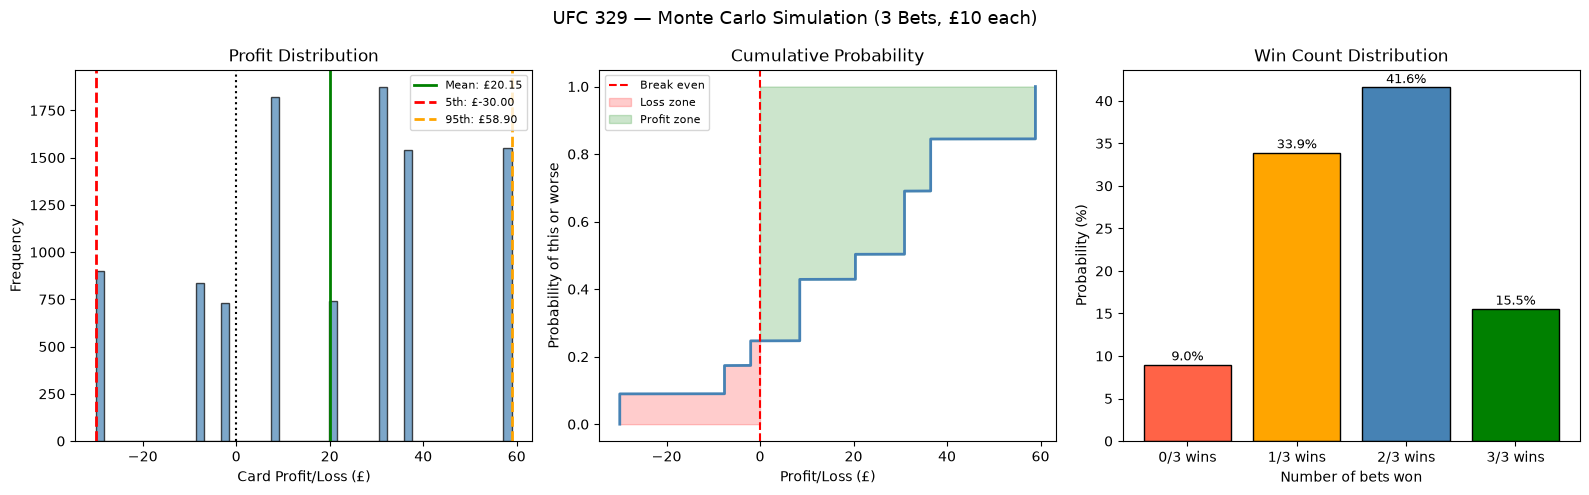

In [20]:
# ── Monte Carlo Simulation — UFC 329 Selected Bets ───────────
import numpy as np
import matplotlib.pyplot as plt

# ── Your selected bets ────────────────────────────────────────
# Fill in from the predictions above
selected_bets = [
    {'fight': 'McGregor vs Holloway',    'our_prob': 0.68, 'bookie_odds': 3.85},
    {'fight': 'Royval vs Kavanagh',      'our_prob': 0.448,'bookie_odds': 2.80},
    {'fight': 'Saint Denis vs Pimblett', 'our_prob': 0.494,'bookie_odds': 2.24},
]

stake       = 10      # £ per bet
n_sims      = 10000   # simulations
model_error = 0.05    # ± uncertainty around our probability

# ── Step 1: EV Analysis ───────────────────────────────────────
print(f"{'='*60}")
print(f"  Bet Analysis")
print(f"{'='*60}")
print(f"  {'Fight':<30} {'Our%':>6} {'Odds':>6} {'Implied':>9} {'EV':>8} {'EV%':>7}")
print(f"  {'-'*58}")

for b in selected_bets:
    implied = 1 / b['bookie_odds']
    profit  = (b['bookie_odds'] - 1) * stake
    ev      = (b['our_prob'] * profit) - ((1 - b['our_prob']) * stake)
    ev_pct  = ev / stake * 100
    print(f"  {b['fight']:<30} {b['our_prob']*100:>5.1f}% {b['bookie_odds']:>6.2f} "
          f"{implied*100:>8.1f}% {ev:>7.2f}  {ev_pct:>6.1f}%")

total_staked = len(selected_bets) * stake
total_ev     = sum((b['our_prob'] * (b['bookie_odds']-1) * stake) -
                   ((1-b['our_prob']) * stake) for b in selected_bets)

print(f"  {'-'*58}")
print(f"  Total staked:     £{total_staked:.2f}")
print(f"  Total expected EV: £{total_ev:.2f}")
print(f"{'='*60}")

# ── Step 2: Monte Carlo ───────────────────────────────────────
sim_profits    = []
win_counts     = []
bet_results    = {b['fight']: [] for b in selected_bets}

for _ in range(n_sims):
    card_profit = 0
    wins        = 0

    for b in selected_bets:
        # Sample probability with uncertainty
        sampled_prob = np.clip(
            np.random.normal(b['our_prob'], model_error),
            0.01, 0.99
        )
        won = np.random.random() < sampled_prob

        if won:
            profit       = (b['bookie_odds'] - 1) * stake
            card_profit += profit
            bet_results[b['fight']].append(profit)
            wins        += 1
        else:
            card_profit -= stake
            bet_results[b['fight']].append(-stake)

    sim_profits.append(card_profit)
    win_counts.append(wins)

sim_profits = np.array(sim_profits)
win_counts  = np.array(win_counts)

# ── Step 3: Results ───────────────────────────────────────────
print(f"\n{'='*60}")
print(f"  Monte Carlo Results ({n_sims:,} simulations)")
print(f"  Stake: £{stake} per bet | Total staked: £{total_staked}")
print(f"{'='*60}")
print(f"  Expected profit:      £{np.mean(sim_profits):>8.2f}")
print(f"  Median profit:        £{np.median(sim_profits):>8.2f}")
print(f"  Best case  (95th):    £{np.percentile(sim_profits, 95):>8.2f}")
print(f"  Worst case (5th):     £{np.percentile(sim_profits, 5):>8.2f}")
print(f"  Std deviation:        £{np.std(sim_profits):>8.2f}")
print(f"  Cards profitable:     {(sim_profits > 0).mean()*100:>7.1f}%")
print(f"  Break even+:          {(sim_profits >= 0).mean()*100:>7.1f}%")
print(f"  Cards at loss:        {(sim_profits < 0).mean()*100:>7.1f}%")
print(f"{'='*60}")

# ── Win count distribution ────────────────────────────────────
print(f"\n  Win count distribution:")
print(f"  {'Wins':>6} {'Frequency':>12} {'Probability':>13}")
print(f"  {'-'*33}")
for w in range(len(selected_bets)+1):
    freq = (win_counts == w).sum()
    prob = freq / n_sims * 100
    bar  = '█' * int(prob / 2)
    print(f"  {w:>4}/3  {freq:>8}  ({prob:>5.1f}%)  {bar}")

# ── Per bet win rate ──────────────────────────────────────────
print(f"\n  Per bet performance across {n_sims:,} simulations:")
print(f"  {'Fight':<30} {'Win Rate':>10} {'Avg Return':>12}")
print(f"  {'-'*55}")
for b in selected_bets:
    res      = np.array(bet_results[b['fight']])
    win_rate = (res > 0).mean() * 100
    avg_ret  = res.mean()
    print(f"  {b['fight']:<30} {win_rate:>9.1f}% £{avg_ret:>9.2f}")

# ── Plots ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('UFC 329 — Monte Carlo Simulation (3 Bets, £10 each)', fontsize=13)

# Plot 1: Profit distribution
axes[0].hist(sim_profits, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
axes[0].axvline(np.mean(sim_profits),           color='green',  lw=2, label=f"Mean: £{np.mean(sim_profits):.2f}")
axes[0].axvline(np.percentile(sim_profits, 5),  color='red',    lw=2, linestyle='--', label=f"5th: £{np.percentile(sim_profits,5):.2f}")
axes[0].axvline(np.percentile(sim_profits, 95), color='orange', lw=2, linestyle='--', label=f"95th: £{np.percentile(sim_profits,95):.2f}")
axes[0].axvline(0, color='black', lw=1.5, linestyle=':')
axes[0].set_title('Profit Distribution')
axes[0].set_xlabel('Card Profit/Loss (£)')
axes[0].set_ylabel('Frequency')
axes[0].legend(fontsize=8)

# Plot 2: Cumulative probability
sorted_p   = np.sort(sim_profits)
cumulative = np.arange(1, n_sims+1) / n_sims
axes[1].plot(sorted_p, cumulative, color='steelblue', lw=2)
axes[1].axvline(0, color='red', lw=1.5, linestyle='--', label='Break even')
axes[1].fill_betweenx(cumulative, sorted_p, 0, where=sorted_p<0, alpha=0.2, color='red',   label='Loss zone')
axes[1].fill_betweenx(cumulative, sorted_p, 0, where=sorted_p>0, alpha=0.2, color='green', label='Profit zone')
axes[1].set_title('Cumulative Probability')
axes[1].set_xlabel('Profit/Loss (£)')
axes[1].set_ylabel('Probability of this or worse')
axes[1].legend(fontsize=8)

# Plot 3: Win count distribution
win_labels = [f'{w}/3 wins' for w in range(len(selected_bets)+1)]
win_probs  = [(win_counts==w).mean()*100 for w in range(len(selected_bets)+1)]
colors     = ['tomato','orange','steelblue','green']
axes[2].bar(win_labels, win_probs, color=colors, edgecolor='black')
axes[2].set_title('Win Count Distribution')
axes[2].set_xlabel('Number of bets won')
axes[2].set_ylabel('Probability (%)')
for i, v in enumerate(win_probs):
    axes[2].text(i, v+0.5, f'{v:.1f}%', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

In [21]:
import pickle

model_data = {
    'scaler':       scaler7,
    'lr':           lr7,
    'rf':           rf7,
    'feature_cols': feature_cols_7,
}

with open('model.pkl', 'wb') as f:
    pickle.dump(model_data, f)

print("Model saved to model.pkl")

Model saved to model.pkl


In [22]:
# ── Neural Network (MLPClassifier) ───────────────────────────────────────────
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, log_loss, brier_score_loss

nn_model = MLPClassifier(
    hidden_layer_sizes=( 128, 64, 32),  # three layers, more nodes  # two hidden layers: 64 nodes → 32 nodes
    activation='relu',
    solver='adam',
    max_iter=1000,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1
)

# Train on same data as your other 7-feature models
nn_model.fit(X_train_s, y_train)  # uses scaler7-scaled training data

# Period 1: 2019-2021
nn_p1 = nn_model.predict_proba(X_test1_s)[:, 1]

# Out of sample: 2022-2026
nn_oos = nn_model.predict_proba(X7_oos)[:, 1]
y_oos  = oos_clean['result']

print("── Neural Network Results ──────────────────────────────")
print(f"  {'Metric':<20} {'2019-2021':>10} {'2022-2026':>10}")
print(f"  {'-'*42}")
print(f"  {'Accuracy':<20} {accuracy_score(y_test1, (nn_p1>=0.5).astype(int)):>10.1%} {accuracy_score(y_oos, (nn_oos>=0.5).astype(int)):>10.1%}")
print(f"  {'Log Loss':<20} {log_loss(y_test1, nn_p1):>10.4f} {log_loss(y_oos, nn_oos):>10.4f}")
print(f"  {'Brier Score':<20} {brier_score_loss(y_test1, nn_p1):>10.4f} {brier_score_loss(y_oos, nn_oos):>10.4f}")

── Neural Network Results ──────────────────────────────
  Metric                2019-2021  2022-2026
  ------------------------------------------
  Accuracy                  60.6%      64.1%
  Log Loss                 0.6650     0.6406
  Brier Score              0.2362     0.2248


In [23]:
nn_train = nn_model.predict_proba(X_train_s)[:, 1]
print(f"  In-sample accuracy (2010-2018): {accuracy_score(y_train, (nn_train>=0.5).astype(int)):.1%}")

  In-sample accuracy (2010-2018): 63.0%


In [24]:
# ── Neural Network Confidence Bands ──────────────────────────
nn_train_probs = nn_model.predict_proba(X_train_s)[:, 1]

print("── Neural Network Confidence Bands ─────────────────────")
print("\n  2010-2018 (Training):")
conf_bands(nn_train_probs, y_train.values, 'Neural Network — 2010-2018')

print("\n  2019-2021 (Test):")
conf_bands(nn_p1, y_test1.values, 'Neural Network — 2019-2021')

print("\n  2022-2026 (Out of Sample):")
conf_bands(nn_oos, y_oos.values, 'Neural Network — 2022-2026')

── Neural Network Confidence Bands ─────────────────────

  2010-2018 (Training):

  Confidence Bands — Neural Network — 2010-2018
  Band           Fights   Win Rate
  --------------------------------
  50-60%           1771     55.3%
  60-70%           1186     65.9%
  70-80%            620     76.1%
  80-90%            100     83.0%
  90-100%             3    100.0%

  2019-2021 (Test):

  Confidence Bands — Neural Network — 2019-2021
  Band           Fights   Win Rate
  --------------------------------
  50-60%            545     55.4%
  60-70%            357     63.3%
  70-80%            156     68.6%
  80-90%             30     80.0%

  2022-2026 (Out of Sample):

  Confidence Bands — Neural Network — 2022-2026
  Band           Fights   Win Rate
  --------------------------------
  50-60%           1205     57.6%
  60-70%            702     67.2%
  70-80%            369     75.9%
  80-90%             66     81.8%
  90-100%             2    100.0%


In [25]:
# ── Neural Network — PyTorch ──────────────────────────────────
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# ── 1. Convert data to PyTorch tensors ───────────────────────
X_train_t  = torch.FloatTensor(X_train_s)
y_train_t  = torch.FloatTensor(y_train.values)
X_test1_t  = torch.FloatTensor(X_test1_s)
X_oos_t    = torch.FloatTensor(X_oos)

# ── 2. DataLoader (batched training — industry standard) ─────
dataset    = TensorDataset(X_train_t, y_train_t)
loader     = DataLoader(dataset, batch_size=32, shuffle=True)

# ── 3. Define network architecture ───────────────────────────
class UFCNet(nn.Module):
    def __init__(self):
        super(UFCNet, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(7, 128),    # input layer  → 128 nodes
            nn.ReLU(),
            nn.Dropout(0.5),      # regularisation — randomly drops 30% of nodes each batch
            nn.Linear(128, 64),   # 128 → 64
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(64, 32),    # 64 → 32
            nn.ReLU(),
            nn.Linear(32, 1),     # 32 → output
            nn.Sigmoid()          # squash to probability
        )

    def forward(self, x):
        return self.network(x).squeeze()

# ── 4. Initialise model, loss function, optimiser ────────────
torch.manual_seed(42)
pt_model   = UFCNet()
criterion  = nn.BCELoss()          # binary cross-entropy loss
optimizer  = optim.Adam(pt_model.parameters(), lr=0.001)

# ── 5. Training loop ─────────────────────────────────────────
EPOCHS = 100
for epoch in range(EPOCHS):
    pt_model.train()
    epoch_loss = 0
    for X_batch, y_batch in loader:
        optimizer.zero_grad()           # clear gradients
        predictions = pt_model(X_batch)
        loss = criterion(predictions, y_batch)
        loss.backward()                 # backpropagation
        optimizer.step()                # update weights
        epoch_loss += loss.item()

    if (epoch + 1) % 20 == 0:
        print(f"  Epoch {epoch+1}/{EPOCHS} — Loss: {epoch_loss/len(loader):.4f}")

# ── 6. Evaluate ───────────────────────────────────────────────
pt_model.eval()
with torch.no_grad():
    pt_train_probs = pt_model(X_train_t).numpy()
    pt_p1          = pt_model(X_test1_t).numpy()
    pt_oos         = pt_model(X_oos_t).numpy()

print(f"\n── PyTorch Neural Network Results ──────────────────────")
print(f"  {'Metric':<20} {'2010-2018':>10} {'2019-2021':>10} {'2022-2026':>10}")
print(f"  {'-'*52}")
print(f"  {'Accuracy':<20} {accuracy_score(y_train, (pt_train_probs>=0.5).astype(int)):>10.1%} {accuracy_score(y_test1, (pt_p1>=0.5).astype(int)):>10.1%} {accuracy_score(y_oos, (pt_oos>=0.5).astype(int)):>10.1%}")
print(f"  {'Log Loss':<20} {log_loss(y_train, pt_train_probs):>10.4f} {log_loss(y_test1, pt_p1):>10.4f} {log_loss(y_oos, pt_oos):>10.4f}")
print(f"  {'Brier Score':<20} {brier_score_loss(y_train, pt_train_probs):>10.4f} {brier_score_loss(y_test1, pt_p1):>10.4f} {brier_score_loss(y_oos, pt_oos):>10.4f}")

  Epoch 20/100 — Loss: 0.6510
  Epoch 40/100 — Loss: 0.6421
  Epoch 60/100 — Loss: 0.6400
  Epoch 80/100 — Loss: 0.6389
  Epoch 100/100 — Loss: 0.6337

── PyTorch Neural Network Results ──────────────────────
  Metric                2010-2018  2019-2021  2022-2026
  ----------------------------------------------------
  Accuracy                  66.0%      58.7%      62.7%
  Log Loss                 0.6173     0.6758     0.6512
  Brier Score              0.2143     0.2408     0.2294


In [29]:
# ── Consensus Ensemble — Hybrid + sklearn NN ─────────────────
THRESHOLD = 0.05

# 2010-2018 (in-sample)
nn_train_probs = nn_model.predict_proba(X_train_s)[:, 1]
hyb_train      = get_hybrid(lr7.predict_proba(X_train_s)[:, 1], rf7.predict_proba(X_train_s)[:, 1])

diff_train      = np.abs(hyb_train - nn_train_probs)
consensus_train = diff_train <= THRESHOLD

# 2019-2021
diff_p1      = np.abs(hyb_p1 - nn_p1)
consensus_p1 = diff_p1 <= THRESHOLD

# 2022-2026
diff_oos      = np.abs(hyb_p2 - nn_oos)
consensus_oos = diff_oos <= THRESHOLD

# Average probabilities where models agree
ensemble_train = (hyb_train[consensus_train] + nn_train_probs[consensus_train]) / 2
ensemble_p1    = (hyb_p1[consensus_p1]       + nn_p1[consensus_p1])             / 2
ensemble_oos   = (hyb_p2[consensus_oos]      + nn_oos[consensus_oos])           / 2

y_train_consensus = y_train.values[consensus_train]
y_test1_consensus = y_test1.values[consensus_p1]
y_oos_consensus   = y_oos[consensus_oos]

print("── Consensus Ensemble Results ───────────────────────────")
print(f"  Agreement threshold: ±{THRESHOLD*100:.1f}%")
print()
print(f"  2010-2018 (in-sample):")
print(f"    Fights with consensus: {consensus_train.sum()} / {len(consensus_train)} ({consensus_train.mean():.1%})")
print(f"    Accuracy: {accuracy_score(y_train_consensus, (ensemble_train>=0.5).astype(int)):.1%}")
print()
print(f"  2019-2021:")
print(f"    Fights with consensus: {consensus_p1.sum()} / {len(consensus_p1)} ({consensus_p1.mean():.1%})")
print(f"    Accuracy: {accuracy_score(y_test1_consensus, (ensemble_p1>=0.5).astype(int)):.1%}")
print()
print(f"  2022-2026:")
print(f"    Fights with consensus: {consensus_oos.sum()} / {len(consensus_oos)} ({consensus_oos.mean():.1%})")
print(f"    Accuracy: {accuracy_score(y_oos_consensus, (ensemble_oos>=0.5).astype(int)):.1%}")

── Consensus Ensemble Results ───────────────────────────
  Agreement threshold: ±5.0%

  2010-2018 (in-sample):
    Fights with consensus: 2833 / 3680 (77.0%)
    Accuracy: 63.1%

  2019-2021:
    Fights with consensus: 840 / 1088 (77.2%)
    Accuracy: 60.5%

  2022-2026:
    Fights with consensus: 1713 / 2344 (73.1%)
    Accuracy: 64.0%


In [30]:
import pickle

# Load existing model.pkl and add the neural network
with open('model.pkl', 'rb') as f:
    model_data = pickle.load(f)

model_data['nn'] = nn_model  # your sklearn (128,64,32) neural network

with open('model.pkl', 'wb') as f:
    pickle.dump(model_data, f)

print("model.pkl updated with neural network")

model.pkl updated with neural network
